# 01 · Limpieza de datos del Nasdaq 100 point-in-time

**Dataset de partida:** `NASDAQ100_PIT_1993-10-01_2026-05-29_CON_HUECOS/` (componentes históricos del Nasdaq 100, incluidas las deslistadas, con sus periodos de pertenencia, desde el 01/10/1993 hasta el 29/05/2026).

**Problema:** al ~3 % de las filas del panel (valor × día de pertenencia) les falta el precio. El propio dataset lo documenta (`LEEME.md`, `ESTADO_DATASET.json`, `resumen_huecos_por_valor`, `tramos_sin_precio`, `miembros_sin_precio`): la mayoría proceden de particiones dañadas en la fuente original, que no se pueden recuperar.

**Objetivo del notebook:** construir un panel limpio y trazable que:

1. respete la **pertenencia point-in-time** (qué valores estaban en el índice cada día, incluidas las deslistadas) para evitar el **sesgo de supervivencia**;
2. trate los huecos con reglas **explícitas, parametrizadas y reproducibles**, usando solo información pasada (sin **look-ahead bias**);
3. no invente precios donde no hay base para ello y **marque** todo lo imputado o no utilizable con columnas indicadoras.

**Reglas de trabajo**

- Los archivos originales **no se modifican**: todo se escribe en `datos_limpios/`.
- Se usan los `.parquet` (no los CSV) y se cargan solo las columnas necesarias.
- Cada decisión de limpieza tiene su propia función y un bloque **Decisión / Por qué** que la justifica.

| Sección | Contenido |
|---|---|
| 0 | Configuración y parámetros |
| 1 | Carga y verificación de integridad |
| 2 | Universo y pertenencia point-in-time |
| 3 | Diagnóstico de huecos |
| 4 | Política de limpieza (una función por decisión) |
| 5 | Validaciones posteriores, incluida la prueba de ausencia de look-ahead |
| 6 | Informe antes / después |
| 7 | Exportación |

## 0. Configuración

Rutas relativas a la raíz del proyecto, para que el notebook funcione desde `notebooks/` sin tocar nada:

```
TFM/
├── NASDAQ100_PIT_..._CON_HUECOS/   ← original, solo lectura
├── notebooks/01_limpieza_datos.ipynb
├── datos_limpios/                  ← salidas de este notebook
└── requirements.txt                ← versiones exactas de las librerías
```

**Reproducibilidad:** `python3 -m pip install -r requirements.txt` instala las mismas versiones con las que se ha ejecutado el notebook (Python 3.11). La celda siguiente imprime las versiones en uso, y estas también quedan guardadas en `informe_limpieza.json`.

In [1]:
import hashlib
import json
import platform
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq

NOMBRE_DATASET = 'NASDAQ100_PIT_1993-10-01_2026-05-29_CON_HUECOS'
# Buscamos la raíz del proyecto subiendo desde el directorio actual
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / NOMBRE_DATASET).is_dir())
DIR_ORIGEN = RAIZ / NOMBRE_DATASET
DIR_SALIDA = RAIZ / 'datos_limpios'
DIR_SALIDA.mkdir(exist_ok=True)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

T_INICIO = time.time()
print('Raíz del proyecto :', RAIZ)
print('Datos originales  :', DIR_ORIGEN)
print('Salida            :', DIR_SALIDA)
print('Python', platform.python_version(), '| pandas', pd.__version__, '| pyarrow', pa.__version__)

Raíz del proyecto : /Users/andrealaba/Desktop/TFM
Datos originales  : /Users/andrealaba/Desktop/TFM/NASDAQ100_PIT_1993-10-01_2026-05-29_CON_HUECOS
Salida            : /Users/andrealaba/Desktop/TFM/datos_limpios
Python 3.11.9 | pandas 3.0.0 | pyarrow 23.0.1


### Parámetros de limpieza

Todos los umbrales están aquí. Cambiar un valor y volver a ejecutar el notebook completo regenera el panel limpio y el informe (los parámetros usados se guardan en `datos_limpios/informe_limpieza.json`).

| Parámetro | Valor | Significado |
|---|---|---|
| `FFILL_MAX_SESIONES` | 5 | Máximo de sesiones consecutivas sin precio que se rellenan con el último precio conocido. Cubre las suspensiones observadas (WorldCom, 3 sesiones; Adelphia, 5 sesiones). |
| `UMBRAL_HUECOS_VALOR` | `None` | Opción A (descartar valores enteros con más de X % de huecos). **Desactivada**: se elige la opción B (ver sección 4.4). |
| `UMBRAL_RET_ANOMALO` | 0,50 | Retornos diarios con \|r\| > 50 % se marcan para revisión (no se borran). |
| `UMBRAL_DIF_AJUSTE` | 0,20 | Diferencia entre el retorno sin ajustar y el ajustado a partir de la cual consideramos que hubo una operación corporativa (split, contrasplit, dividendo especial). |
| `TOL_SPLIT` | 0,02 | Tolerancia relativa para decidir si un salto de precio parece un factor de split entero (2:1, 3:1…). |
| `TOL_OHLC` | 1e-6 | Tolerancia relativa al comprobar `low ≤ open, close ≤ high`. |
| `RACHA_CONGELADO` | 5 | Número de sesiones seguidas con exactamente el mismo cierre sin ajustar a partir del cual el precio se marca como congelado. |
| `CORTES_TEST_LOOKAHEAD` | 3 fechas | Fechas en las que se trunca el dataset para comprobar que la limpieza no usa información futura (sección 5.8). |

In [2]:
PARAMS = {
    'FFILL_MAX_SESIONES': 5,
    'UMBRAL_HUECOS_VALOR': None,   # p. ej. 0.5 para activar la opción A (no recomendado)
    'UMBRAL_RET_ANOMALO': 0.50,
    'UMBRAL_DIF_AJUSTE': 0.20,
    'TOL_SPLIT': 0.02,
    'TOL_OHLC': 1e-6,
    'RACHA_CONGELADO': 5,
    # Cortes elegidos a propósito en mitad de huecos: suspensión de WorldCom (2002),
    # inicio del hueco de WBD (2014) e inicio del hueco de TMUS (2018)
    'CORTES_TEST_LOOKAHEAD': ['2002-06-27', '2014-01-06', '2018-01-04'],
}
VARIANTES = ['none', 'capital', 'capitalspecial', 'totalreturn']
PARAMS

{'FFILL_MAX_SESIONES': 5,
 'UMBRAL_HUECOS_VALOR': None,
 'UMBRAL_RET_ANOMALO': 0.5,
 'UMBRAL_DIF_AJUSTE': 0.2,
 'TOL_SPLIT': 0.02,
 'TOL_OHLC': 1e-06,
 'RACHA_CONGELADO': 5,
 'CORTES_TEST_LOOKAHEAD': ['2002-06-27', '2014-01-06', '2018-01-04']}

### Estilo de los gráficos

Paleta categórica fija (mismo orden siempre), trazos finos, rejilla discreta y etiquetas directas, para que los gráficos se puedan leer sin depender solo del color.

In [3]:
COLOR = {'azul': '#2a78d6', 'naranja': '#eb6834', 'aqua': '#1baf7a', 'amarillo': '#eda100'}
FONDO, TINTA, TINTA_2 = '#fcfcfb', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': FONDO, 'axes.facecolor': FONDO,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'lines.linewidth': 2, 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'text.color': TINTA, 'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'legend.frameon': False,
})

## 1. Carga y verificación de integridad

### 1.1 Huellas SHA256

Antes de usar nada comprobamos que los archivos son exactamente los entregados: recalculamos el SHA256 de cada archivo listado en `SHA256SUMS.txt` y verificamos que no haya archivos extra sin listar. Si algo no cuadra, el notebook se detiene.

In [4]:
def sha256_archivo(ruta, bloque=1 << 20):
    # Hash por bloques para no cargar archivos grandes en memoria
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for trozo in iter(lambda: f.read(bloque), b''):
            h.update(trozo)
    return h.hexdigest()


def verificar_integridad(directorio):
    esperado = pd.read_csv(directorio / 'SHA256SUMS.txt', sep=r'\s+', header=None,
                           names=['sha256_esperado', 'archivo'], engine='python')
    esperado['sha256_calculado'] = [sha256_archivo(directorio / a) for a in esperado['archivo']]
    esperado['ok'] = esperado['sha256_esperado'] == esperado['sha256_calculado']
    presentes = {p.relative_to(directorio).as_posix() for p in directorio.rglob('*')
                 if p.is_file() and p.name != '.DS_Store'} - {'SHA256SUMS.txt'}
    no_listados = sorted(presentes - set(esperado['archivo']))
    return esperado, no_listados


t0 = time.time()
integridad, no_listados = verificar_integridad(DIR_ORIGEN)
print(f'Archivos verificados: {len(integridad)} | correctos: {integridad.ok.sum()} | '
      f'no listados: {len(no_listados)} | {time.time() - t0:.1f} s')
assert integridad['ok'].all(), integridad.loc[~integridad['ok'], 'archivo'].tolist()
assert not no_listados, no_listados
HASHES_ENTRADA = dict(zip(integridad['archivo'], integridad['sha256_calculado']))

Archivos verificados: 75 | correctos: 75 | no listados: 0 | 0.5 s


### 1.2 Esquemas

Comparamos el esquema real de cada `.parquet` (nombres, tipos y número de filas, leídos solo de los metadatos, sin cargar datos) con `diccionario_esquemas.json`.

In [5]:
diccionario = json.loads((DIR_ORIGEN / 'diccionario_esquemas.json').read_text())
filas = []
for tabla in diccionario:
    ruta = DIR_ORIGEN / tabla['file']
    real = [(c.name, str(c.type)) for c in pq.read_schema(ruta)]
    esperado = [(c['name'], c['type']) for c in tabla['columns']]
    filas.append({'archivo': tabla['file'], 'filas_esperadas': tabla['rows'],
                  'filas_reales': pq.ParquetFile(ruta).metadata.num_rows,
                  'columnas': len(real), 'esquema_ok': real == esperado})
esquemas = pd.DataFrame(filas)
esquemas['filas_ok'] = esquemas['filas_esperadas'] == esquemas['filas_reales']
display(esquemas)
assert esquemas[['esquema_ok', 'filas_ok']].all().all()

,archivo,filas_esperadas,filas_reales,columnas,esquema_ok,filas_ok
0,calendario_y_cobertura.parquet,8220,8220,6,True,True
1,eventos_indice.parquet,1001,1001,5,True,True
2,indices_referencia.parquet,17262,17262,9,True,True
3,miembros_sin_precio.parquet,24975,24975,48,True,True
4,panel_pit_diario.parquet,830759,830759,48,True,True
5,pertenencia_diaria.parquet,830759,830759,4,True,True
6,pertenencia_periodos.parquet,551,551,14,True,True
7,pertenencia_rangos_fuente.parquet,551,551,6,True,True
8,precios_diarios.parquet,2300136,2300136,48,True,True
9,resumen_huecos_por_valor.parquet,28,28,12,True,True


### 1.3 Carga selectiva

- Tablas pequeñas (calendario, universo, pertenencia, resúmenes de huecos, índices): se cargan enteras.
- `panel_pit_diario.parquet` (830.759 filas × 48 columnas) y `precios_diarios.parquet` (2,3 M filas × 48 columnas): **solo las columnas necesarias**. El panel completo se lee una única vez, en la exportación (sección 7), para conservar todas sus columnas.

Las fechas se convierten a `datetime64[ns]` en una función común, para que todas las uniones usen el mismo tipo.

In [6]:
def leer(nombre, columnas=None, filtros=None):
    return pd.read_parquet(DIR_ORIGEN / f'{nombre}.parquet', columns=columnas, filters=filtros)


def a_fecha(df, *columnas):
    for c in columnas:
        df[c] = pd.to_datetime(df[c]).astype('datetime64[ns]')
    return df


cal = a_fecha(leer('calendario_y_cobertura'), 'date', 'previous_session', 'next_session')
univ = a_fecha(leer('universo'), 'first_price_date', 'last_price_date', 'first_quoted_date_snapshot',
               'first_included_session_observed', 'last_included_session_observed')
periodos = a_fecha(leer('pertenencia_periodos'), 'first_included_session', 'last_included_session',
                   'entry_effective_date', 'exit_effective_date_inferred')
pert_diaria = a_fecha(leer('pertenencia_diaria'), 'date')
resumen_huecos = a_fecha(leer('resumen_huecos_por_valor'), 'first_missing_session', 'last_missing_session',
                         'first_price_date', 'last_price_date')
tramos_doc = a_fecha(leer('tramos_sin_precio'), 'first_missing_session', 'last_missing_session')
sin_precio_doc = a_fecha(leer('miembros_sin_precio', ['date', 'assetid', 'membership_period']), 'date')
indices = a_fecha(leer('indices_referencia', ['symbol', 'date', 'close']), 'date')

# Panel PIT: solo las columnas que usa la limpieza
COLS_PANEL = ['date', 'assetid', 'membership_period', 'has_price', 'close_totalreturn', 'close_none',
              'previous_price_date', 'return_totalreturn_1_session', 'capital_event', 'volume_none']
panel = a_fecha(leer('panel_pit_diario', COLS_PANEL), 'date', 'previous_price_date')
panel = panel.sort_values(['date', 'assetid'], ignore_index=True)
# Copia sin modificar: se reutiliza en la prueba de look-ahead (sección 5.8)
panel_base = panel.copy()

# Historia completa de precios (también fuera de la pertenencia): necesaria para saber
# cuál era el último precio conocido antes de cada fecha
historia = a_fecha(leer('precios_diarios', ['assetid', 'date', 'close_totalreturn', 'close_none']), 'date')
historia = historia.sort_values(['date', 'assetid'], ignore_index=True)

SIMBOLO = univ.set_index('assetid')['symbol_snapshot']
for nombre, df in [('panel', panel), ('historia de precios', historia)]:
    print(f'{nombre:20s}: {len(df):>9,} filas | {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB')

panel               :   830,759 filas | 57 MB
historia de precios : 2,300,136 filas | 74 MB


## 2. Universo y pertenencia point-in-time

Antes de tocar los precios hay que saber **qué valores estaban en el índice cada día**. Es la base para evitar el sesgo de supervivencia: si solo usáramos las empresas que cotizan hoy, eliminaríamos las que quebraron, fueron adquiridas o salieron del índice, y los resultados saldrían artificialmente buenos.

**Claves de unión**

- **`assetid`** identifica el valor. El símbolo (`symbol_snapshot`) es el del snapshot actual: no sirve como clave histórica.
- **`(date, assetid)`** identifica una fila del panel diario.
- **`(assetid, membership_period)`** identifica un periodo de pertenencia (un valor puede salir y volver a entrar).
- Los extremos de los periodos son **inclusivos**: un valor es miembro el día `d` si `first_included_session ≤ d ≤ last_included_session`.

### 2.1 Calendario de sesiones

Las sesiones válidas son las del índice `$NDX`. Las usamos para contar «sesiones sin precio», de modo que fines de semana y festivos no cuentan nunca como huecos. Para mirar hacia atrás antes del 01/10/1993 (por ejemplo, el último precio de un valor en 1991) extendemos el calendario con todas las sesiones del `$NDX` desde 1985.

In [7]:
sesiones_cal = pd.DatetimeIndex(cal['date'])
assert sesiones_cal.is_monotonic_increasing and sesiones_cal.is_unique
assert (cal['previous_session'].iloc[1:].to_numpy() == cal['date'].iloc[:-1].to_numpy()).all()

assert not indices.duplicated(['symbol', 'date']).any()
ndx = indices[indices['symbol'] == '$NDX'].set_index('date')['close'].sort_index()
ndx_en_cobertura = ndx.loc[sesiones_cal[0]:sesiones_cal[-1]].index
print('Sesiones del calendario == sesiones del $NDX en la cobertura:', ndx_en_cobertura.equals(sesiones_cal))

# Calendario extendido: $NDX desde 1985 + calendario del dataset
SESIONES = pd.DatetimeIndex(sorted(set(ndx.index) | set(sesiones_cal)))
fuera = ~historia['date'].isin(SESIONES)
print(f'Fechas con precio que no son sesión del $NDX: {fuera.sum():,}')
if fuera.any():
    # Si existieran, se añaden al calendario para no contarlas como huecos
    SESIONES = SESIONES.union(pd.DatetimeIndex(historia.loc[fuera, 'date'].unique()))
print(f'Calendario extendido: {SESIONES[0].date()} → {SESIONES[-1].date()} ({len(SESIONES):,} sesiones)')
print(f'Cobertura del panel : {sesiones_cal[0].date()} → {sesiones_cal[-1].date()} ({len(sesiones_cal):,} sesiones)')


def posicion_sesion(fechas):
    # Número de orden de cada fecha en el calendario extendido (NaN si la fecha es nula)
    pos = SESIONES.get_indexer(pd.DatetimeIndex(fechas)).astype(float)
    pos[pos < 0] = np.nan
    return pos

Sesiones del calendario == sesiones del $NDX en la cobertura: True
Fechas con precio que no son sesión del $NDX: 0
Calendario extendido: 1985-01-31 → 2026-05-29 (10,411 sesiones)
Cobertura del panel : 1993-10-01 → 2026-05-29 (8,220 sesiones)


### 2.2 Coherencia entre `pertenencia_periodos`, `pertenencia_diaria` y el panel

Reconstruimos la pertenencia diaria expandiendo cada periodo a sus sesiones, y comprobamos que:

1. coincide exactamente con `pertenencia_diaria`;
2. las claves del panel son exactamente las de `pertenencia_diaria` (el panel no pierde ni añade miembros);
3. ningún valor tiene dos periodos solapados;
4. el número de miembros por sesión coincide con `calendario_y_cobertura`.

In [8]:
def expandir_periodos(periodos, sesiones):
    # Una fila (date, assetid, membership_period) por cada sesión de cada periodo (extremos inclusivos)
    fechas = sesiones.to_numpy()
    ini = np.searchsorted(fechas, periodos['first_included_session'].to_numpy(), side='left')
    fin = np.searchsorted(fechas, periodos['last_included_session'].to_numpy(), side='right')
    n = fin - ini
    idx = np.concatenate([np.arange(a, b) for a, b in zip(ini, fin)])
    return pd.DataFrame({'date': fechas[idx],
                         'assetid': np.repeat(periodos['assetid'].to_numpy(), n),
                         'membership_period': np.repeat(periodos['membership_period'].to_numpy(), n)})


CLAVES = ['date', 'assetid', 'membership_period']
ordenar = lambda df: df[CLAVES].sort_values(CLAVES, ignore_index=True)

expandida = expandir_periodos(periodos, sesiones_cal)
pd.testing.assert_frame_equal(ordenar(expandida), ordenar(pert_diaria), check_dtype=False)
pd.testing.assert_frame_equal(ordenar(panel), ordenar(pert_diaria), check_dtype=False)
assert not expandida.duplicated(['date', 'assetid']).any()
assert pert_diaria['is_nasdaq100_member'].all()

miembros_dia = panel.groupby('date').size()
sin_precio_dia = (~panel['has_price']).groupby(panel['date']).sum()
assert (miembros_dia.to_numpy() == cal['member_count'].to_numpy()).all()
assert (sin_precio_dia.to_numpy() == cal['members_without_price'].to_numpy()).all()
print('✔ periodos → pertenencia diaria → panel: coherentes, sin solapes, conteos iguales al calendario')
print(f'Filas del panel (valor × sesión de pertenencia): {len(panel):,}')

✔ periodos → pertenencia diaria → panel: coherentes, sin solapes, conteos iguales al calendario
Filas del panel (valor × sesión de pertenencia): 830,759


### 2.3 Composición del universo

Resumen de valores, periodos, reentradas y censura. La **censura** indica que no conocemos el extremo real de un periodo: a la izquierda, el valor ya estaba en el índice al empezar la cobertura (1993); a la derecha, sigue en el índice en la fecha de corte (29/05/2026).

In [9]:
n_periodos = periodos.groupby('assetid').size()
resumen_universo = pd.Series({
    'valores (assetid) que alguna vez fueron miembros': panel['assetid'].nunique(),
    'valores en universo.parquet': len(univ),
    '  ... deslistados hoy (is_delisted_snapshot)': int(univ['is_delisted_snapshot'].sum()),
    'periodos de pertenencia': len(periodos),
    'valores con reentradas (más de un periodo)': int((n_periodos > 1).sum()),
    'periodos censurados a la izquierda (ya miembro en 1993)': int(periodos['left_censored'].sum()),
    'periodos censurados a la derecha (miembro al corte)': int(periodos['right_censored'].sum()),
    'periodos cuyo fin coincide con el fin de la serie de precios': int(periodos['endpoint_at_last_price'].sum()),
    'sesiones con menos de 100 miembros': int(cal['member_count_below_100_review'].sum()),
}, name='n')
display(resumen_universo.to_frame())
display(periodos['exit_date_basis'].value_counts().to_frame('periodos'))

,n
valores (assetid) que alguna vez fueron miembros,473
valores en universo.parquet,473
... deslistados hoy (is_delisted_snapshot),255
periodos de pertenencia,551
valores con reentradas (más de un periodo),69
periodos censurados a la izquierda (ya miembro en 1993),97
periodos censurados a la derecha (miembro al corte),101
periodos cuyo fin coincide con el fin de la serie de precios,48
sesiones con menos de 100 miembros,328


,periodos
exit_date_basis,
NEXT_INDEX_SESSION_INFERRED_FROM_RANGE,402
RIGHT_CENSORED_AT_SOURCE_CUTOFF,101
END_OF_PRICE_SERIES_REMOVAL_UNCONFIRMED,48


**Sesiones con menos de 100 miembros (328).** El Nasdaq 100 tiene normalmente 100–103 componentes (algunas empresas tienen dos clases de acciones). Que haya sesiones con 96–99 miembros apunta a lagunas en la fuente de pertenencia, que el propio dataset declara no certificada (`membership_source_completeness_independently_certified = false`). **No se pueden corregir con los datos disponibles**: se documentan y se tienen en cuenta al interpretar resultados de esos años.

In [10]:
bajo_100 = cal.assign(anio=cal['date'].dt.year).groupby('anio').agg(
    sesiones=('date', 'size'), sesiones_menos_100=('member_count_below_100_review', 'sum'),
    min_miembros=('member_count', 'min'), max_miembros=('member_count', 'max'))
display(bajo_100[bajo_100['sesiones_menos_100'] > 0].T)

anio,1993,1994,1998,2001,2008
sesiones,64,252,252,248,253
sesiones_menos_100,64,243,1,19,1
min_miembros,96,96,99,98,99
max_miembros,98,101,100,100,100


### 2.4 Por qué importa conservar las deslistadas

Comparamos los miembros reales de cada día con lo que veríamos si filtráramos por `is_delisted_snapshot = False`, es decir, quedándonos solo con las empresas que siguen cotizando hoy. Ese filtro es justo el error que el `LEEME.md` pide no cometer.

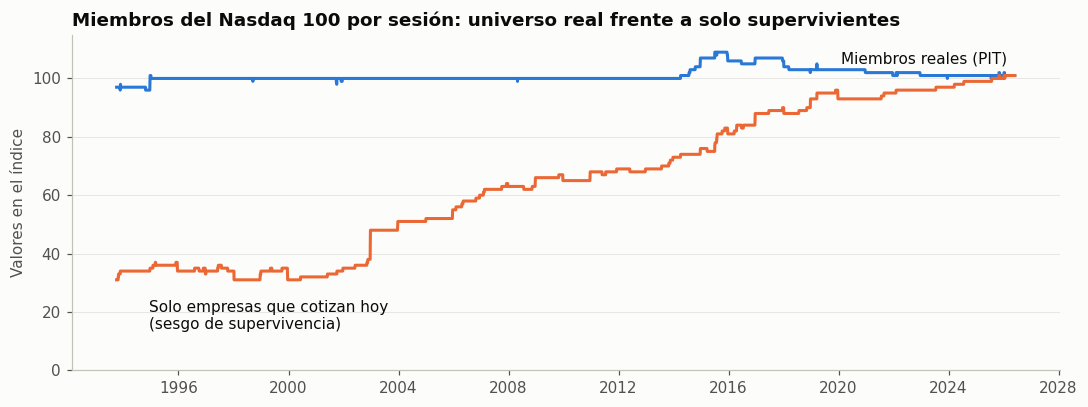

date,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% filas de miembro de empresas hoy deslistadas,66.0000,64.9000,64.1000,65.8000,65.5000,68.9000,65.8000,68.4000,67.1000,63.9000,51.9000,49.0000,47.9000,42.5000,37.9000,...,31.6000,30.2000,27.6000,27.4000,21.1000,17.2000,14.1000,8.1000,9.7000,8.0000,5.8000,4.5000,2.7000,1.5000,0.1000


In [11]:
deslistado = panel['assetid'].map(univ.set_index('assetid')['is_delisted_snapshot'])
miembros = pd.DataFrame({'todos': miembros_dia,
                         'solo_supervivientes': (~deslistado).groupby(panel['date']).sum()})
pct_deslistadas = 100 * deslistado.groupby(panel['date'].dt.year).mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(miembros.index, miembros['todos'], color=COLOR['azul'])
ax.plot(miembros.index, miembros['solo_supervivientes'], color=COLOR['naranja'])
ax.annotate('Miembros reales (PIT)', (miembros.index[-1], miembros['todos'].iloc[-1]),
            xytext=(-5, 8), textcoords='offset points', ha='right', color=TINTA)
ax.annotate('Solo empresas que cotizan hoy\n(sesgo de supervivencia)',
            (miembros.index[300], miembros['solo_supervivientes'].iloc[300]),
            xytext=(0, -38), textcoords='offset points', color=TINTA)
ax.set_ylim(0, 115)
ax.set_ylabel('Valores en el índice')
ax.set_title('Miembros del Nasdaq 100 por sesión: universo real frente a solo supervivientes')
plt.tight_layout()
plt.show()

display(pd.DataFrame({'% filas de miembro de empresas hoy deslistadas': pct_deslistadas}).T.round(1))

> **Decisión:** el universo de cada día es el de `pertenencia_diaria` (equivalente a expandir `pertenencia_periodos`), con todos los valores, coticen hoy o no. Nunca se filtra por `is_delisted_snapshot` ni por ningún otro campo del snapshot actual.
>
> **Por qué:** en los años 90 más de la mitad de los miembros del índice son empresas hoy deslistadas. Quitarlas reduciría el índice a una fracción de su tamaño real y dejaría solo a las ganadoras: sesgo de supervivencia.

## 3. Diagnóstico de huecos

Un **hueco** es una fila del panel (un valor que **sí era miembro** ese día) sin precio (`has_price = False`). En esta sección se describen los huecos sin modificar nada.

> **Nota sobre el look-ahead.** El diagnóstico usa toda la información disponible, incluido el siguiente precio después de un hueco, porque solo sirve para *describir* el problema. Las reglas de limpieza de la sección 4 **no** usan nada posterior a la fecha de cada fila.

### 3.1 Comprobación contra la documentación del dataset

Reproducimos con pandas los criterios de `auditar_huecos.py` (que usa DuckDB y escribe en la carpeta original, por lo que no lo ejecutamos) y comprobamos que obtenemos lo mismo:

- las filas sin precio del panel son exactamente las de `miembros_sin_precio`;
- agrupando sesiones consecutivas sin precio de un mismo valor salen los mismos 39 tramos que `tramos_sin_precio`, con el mismo método: número de sesión − número de fila dentro del valor.

In [12]:
sin_precio = panel.loc[~panel['has_price'], CLAVES].copy()
pd.testing.assert_frame_equal(ordenar(sin_precio), ordenar(sin_precio_doc), check_dtype=False)


def identificar_tramos(filas):
    # Tramo = sesiones consecutivas (en el calendario) sin precio de un mismo valor
    f = filas.sort_values(['assetid', 'date']).copy()
    f['pos'] = posicion_sesion(f['date'])
    f['tramo'] = (f.groupby('assetid')['pos'].diff() != 1).cumsum()
    tramos = f.groupby('tramo').agg(assetid=('assetid', 'first'), inicio=('date', 'min'),
                                    fin=('date', 'max'), sesiones=('date', 'size')).reset_index(drop=True)
    return f, tramos


sin_precio, tramos = identificar_tramos(sin_precio)
doc = tramos_doc.rename(columns={'first_missing_session': 'inicio', 'last_missing_session': 'fin',
                                 'missing_member_sessions': 'sesiones'})
cols_cmp = ['assetid', 'inicio', 'fin', 'sesiones']
pd.testing.assert_frame_equal(tramos[cols_cmp].sort_values(cols_cmp, ignore_index=True),
                              doc[cols_cmp].sort_values(cols_cmp, ignore_index=True), check_dtype=False)
print(f'✔ {len(sin_precio):,} filas sin precio ({100 * len(sin_precio) / len(panel):.3f} % del panel) '
      f'en {len(tramos)} tramos y {tramos.assetid.nunique()} valores: coincide con la documentación')

✔ 24,975 filas sin precio (3.006 % del panel) en 39 tramos y 28 valores: coincide con la documentación


### 3.2 Clasificación de cada tramo

Para cada tramo buscamos el último precio **anterior** y el primer precio **posterior** en la historia completa del valor (también en días en que no era miembro), y medimos el hueco en la **serie de precios**:

| Clase | Criterio | Interpretación |
|---|---|---|
| **A · Sin cotización puntual** | hay precio antes y después, y la serie de precios se interrumpe ≤ `FFILL_MAX_SESIONES` sesiones | Días reales sin negociación: suspensiones (WorldCom, Adelphia), sesiones tras festivos, etc. Es un hueco «verdadero» de mercado, no un error. |
| **B · Prolongado** | hay algún precio anterior, pero la serie se interrumpe más de `FFILL_MAX_SESIONES` sesiones | Pérdida de datos en la fuente (particiones dañadas). No hay forma honesta de reconstruir esos precios. |
| **C · Sin historia previa** | no existe ningún precio anterior del valor | La serie disponible empieza después del hueco (p. ej. empieza en 2015 aunque el valor era miembro en los 90). |

También se añade la evaluación del propio dataset (`assessment` de `resumen_huecos_por_valor`).

In [13]:
fechas_precio = historia[['assetid', 'date']]


def precio_vecino(filas, col_fecha, direccion, nombre):
    # Fecha del precio real más cercano estrictamente antes ('backward') o después ('forward')
    derecha = fechas_precio.assign(**{nombre: fechas_precio['date']})[['assetid', nombre]]
    izquierda = filas.sort_values(col_fecha)
    return pd.merge_asof(izquierda, derecha, left_on=col_fecha, right_on=nombre, by='assetid',
                         direction=direccion, allow_exact_matches=False)


F = PARAMS['FFILL_MAX_SESIONES']
tramos = precio_vecino(tramos, 'inicio', 'backward', 'precio_anterior')
tramos = precio_vecino(tramos, 'fin', 'forward', 'precio_posterior')
tramos['hueco_serie_sesiones'] = (posicion_sesion(tramos['precio_posterior'])
                                  - posicion_sesion(tramos['precio_anterior']) - 1)
tramos['clase'] = np.select(
    [tramos['precio_anterior'].isna(), tramos['hueco_serie_sesiones'].le(F)],
    ['C · sin historia previa', 'A · sin cotización puntual'], default='B · prolongado')
tramos['simbolo'] = tramos['assetid'].map(SIMBOLO)
tramos['evaluacion_fuente'] = tramos['assetid'].map(resumen_huecos.set_index('assetid')['assessment'])
tramos = tramos.sort_values(['clase', 'sesiones'], ascending=[True, False], ignore_index=True)

display(pd.crosstab(tramos['evaluacion_fuente'], tramos['clase'], margins=True, margins_name='total'))
display(tramos[['simbolo', 'assetid', 'inicio', 'fin', 'sesiones', 'precio_anterior', 'precio_posterior',
                'hueco_serie_sesiones', 'clase']])

clase,A · sin cotización puntual,B · prolongado,C · sin historia previa,total
evaluacion_fuente,,,,
ISOLATED_GAPS_CAUSE_UNCONFIRMED,18,0,0,18
PROLONGED_GAPS_MATCH_HISTORICAL_DAMAGED_PARTITIONS,0,12,9,21
total,18,12,9,39


,simbolo,assetid,inicio,fin,sesiones,precio_anterior,precio_posterior,hueco_serie_sesiones,clase
0,ADELQ-200702,132552,2002-05-16,2002-05-22,5,2002-05-15,2002-05-23,5.0000,A · sin cotización puntual
1,WCOEQ-200404,267317,2002-06-26,2002-06-28,3,2002-06-25,2002-07-01,3.0000,A · sin cotización puntual
2,PLIT-199707,259352,1993-10-18,1993-10-19,2,1993-10-15,1993-10-20,2.0000,A · sin cotización puntual
3,BIIB,131713,2006-03-07,2006-03-08,2,2006-03-06,2006-03-09,2.0000,A · sin cotización puntual
4,PTCM-199509,257772,1993-11-26,1993-11-26,1,1993-11-24,1993-11-29,1.0000,A · sin cotización puntual
5,PTCM-199509,257772,1994-11-25,1994-11-25,1,1994-11-23,1994-11-28,1.0000,A · sin cotización puntual
6,PTCM-199509,257772,1995-05-09,1995-05-09,1,1995-05-08,1995-05-10,1.0000,A · sin cotización puntual
7,CHIR-200604,145367,1996-06-07,1996-06-07,1,1996-06-06,1996-06-10,1.0000,A · sin cotización puntual
8,CHIR-200604,145367,1997-05-08,1997-05-08,1,1997-05-07,1997-05-09,1.0000,A · sin cotización puntual
9,IMNX-200207,267293,1998-09-16,1998-09-16,1,1998-09-15,1998-09-17,1.0000,A · sin cotización puntual


**Lectura.** Las 26 filas (18 tramos) que el dataset califica como «aislados, causa no confirmada» son todas de clase A, tan pocas que en el gráfico de la sección 3.4 no llegan a verse: el valor cotiza el día anterior y el siguiente, y caen en fechas compatibles con suspensiones conocidas (WorldCom, junio de 2002; Adelphia, mayo de 2002) o en días de sesión reducida. Los tramos de los 16 valores con «particiones dañadas» son B o C: faltan meses o años enteros de la serie de precios, no solo días sueltos. Varios valores (CIEN, FSLR, EQIX, HNI, FOSL, QLGC, EFII) **no tienen ningún precio durante toda su pertenencia**.

### 3.3 Por valor

In [14]:
sin_precio = sin_precio.merge(tramos[['assetid', 'inicio', 'clase']], on='assetid', how='left')
sin_precio = sin_precio[sin_precio['date'] >= sin_precio['inicio']]
sin_precio = sin_precio.sort_values('inicio').drop_duplicates(['date', 'assetid'], keep='last')
assert len(sin_precio) == (~panel['has_price']).sum()

sesiones_miembro = panel.groupby('assetid').size()
por_valor = (resumen_huecos.set_index('assetid')
             [['symbol_snapshot', 'is_delisted_snapshot', 'missing_member_sessions', 'assessment']]
             .rename(columns={'symbol_snapshot': 'simbolo', 'is_delisted_snapshot': 'deslistado',
                              'missing_member_sessions': 'sesiones_sin_precio', 'assessment': 'evaluacion_fuente'}))
por_valor['sesiones_miembro'] = sesiones_miembro.reindex(por_valor.index)
por_valor['pct_sin_precio'] = 100 * por_valor['sesiones_sin_precio'] / por_valor['sesiones_miembro']
por_valor['tramos'] = tramos.groupby('assetid').size()
display(por_valor.sort_values('sesiones_sin_precio', ascending=False))
print(f"Valores con huecos: {len(por_valor)} de {panel['assetid'].nunique()} "
      f"({int(por_valor['deslistado'].sum())} deslistados hoy)")

,simbolo,deslistado,sesiones_sin_precio,evaluacion_fuente,sesiones_miembro,pct_sin_precio,tramos
assetid,,,,,,,
144108,BBBYQ-202309,True,4536,PROLONGED_GAPS_MATCH_HISTORICAL_DAMAGED_PARTIT...,5031,90.1610,1
136428,AABA-201910,True,4100,PROLONGED_GAPS_MATCH_HISTORICAL_DAMAGED_PARTIT...,4719,86.8828,1
145519,LRCX,False,3073,PROLONGED_GAPS_MATCH_HISTORICAL_DAMAGED_PARTIT...,5941,51.7253,3
125619,NOVL-201104,True,2010,PROLONGED_GAPS_MATCH_HISTORICAL_DAMAGED_PARTIT...,2074,96.9142,1
142195,MLKN,False,1640,PROLONGED_GAPS_MATCH_HISTORICAL_DAMAGED_PARTIT...,1704,96.2441,2
131183,QLGC-201608,True,1508,PROLONGED_GAPS_MATCH_HISTORICAL_DAMAGED_PARTIT...,1508,100.0000,1
127575,EXC,False,1285,PROLONGED_GAPS_MATCH_HISTORICAL_DAMAGED_PARTIT...,1637,78.4973,1
129132,CIEN,False,1102,PROLONGED_GAPS_MATCH_HISTORICAL_DAMAGED_PARTIT...,1102,100.0000,1
168627,WBD,False,1014,PROLONGED_GAPS_MATCH_HISTORICAL_DAMAGED_PARTIT...,2875,35.2696,3


Valores con huecos: 28 de 473 (13 deslistados hoy)


### 3.4 Por año

Porcentaje de filas del panel sin precio cada año, desglosado por clase de tramo. El ~3 % global no está repartido de forma uniforme: se concentra en 1994–2014 y en 2018–2024.

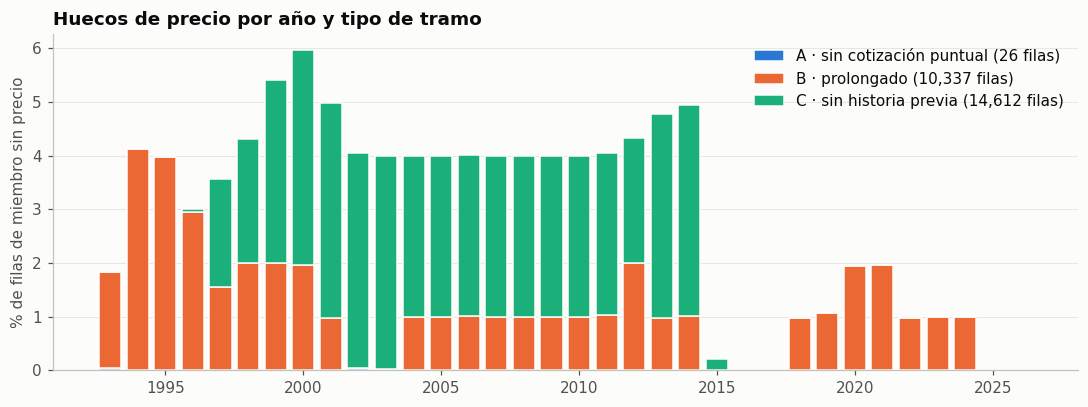

anio,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
clase,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A · sin cotización puntual,0.0500,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0400,0.0000,0.0000,0.0000,0.0100,0.0000,...,0.0000,0.0000,0.0000,0.0100,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
B · prolongado,1.7900,4.1200,3.9600,2.9500,1.5600,2.0000,2.0000,1.9600,0.9800,0.0000,0.0300,1.0000,1.0000,1.0000,1.0000,...,2.0000,0.9800,1.0100,0.0000,0.0000,0.0000,0.9700,1.0700,1.9400,1.9600,0.9800,0.9900,0.9900,0.0000,0.0000
C · sin historia previa,0.0000,0.0000,0.0000,0.0500,2.0000,2.3000,3.4200,4.0000,4.0000,4.0000,3.9700,3.0000,3.0000,3.0000,3.0000,...,2.3200,3.8000,3.9300,0.2000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
total_pct,1.8400,4.1300,3.9700,3.0000,3.5600,4.3000,5.4200,5.9600,4.9800,4.0400,4.0000,4.0000,4.0000,4.0100,4.0000,...,4.3200,4.7700,4.9300,0.2100,0.0000,0.0000,0.9700,1.0700,1.9500,1.9600,0.9800,0.9900,0.9900,0.0000,0.0000
filas_sin_precio,114.0000,"1,009.0000","1,000.0000",763.0000,901.0000,"1,084.0000","1,365.0000","1,503.0000","1,235.0000","1,018.0000","1,008.0000","1,008.0000","1,008.0000","1,006.0000","1,004.0000",...,"1,081.0000","1,203.0000","1,267.0000",57.0000,0.0000,0.0000,251.0000,279.0000,507.0000,504.0000,251.0000,251.0000,252.0000,0.0000,0.0000
filas_panel,"6,208.0000","24,440.0000","25,200.0000","25,400.0000","25,300.0000","25,199.0000","25,200.0000","25,200.0000","24,778.0000","25,200.0000","25,200.0000","25,200.0000","25,200.0000","25,100.0000","25,100.0000",...,"25,000.0000","25,200.0000","25,678.0000","27,185.0000","26,594.0000","26,848.0000","25,901.0000","25,958.0000","26,051.0000","25,695.0000","25,567.0000","25,248.0000","25,452.0000","25,249.0000","10,309.0000"


In [15]:
anio_panel = panel['date'].dt.year
por_anio = (sin_precio.assign(anio=sin_precio['date'].dt.year)
            .pivot_table(index='anio', columns='clase', values='assetid', aggfunc='size', fill_value=0)
            .reindex(sorted(anio_panel.unique()), fill_value=0))
filas_anio = anio_panel.value_counts().sort_index()
pct_anio = 100 * por_anio.div(filas_anio, axis=0)

fig, ax = plt.subplots(figsize=(10, 3.8))
base = np.zeros(len(pct_anio))
colores_clase = [COLOR['azul'], COLOR['naranja'], COLOR['aqua']]
for clase, color in zip(pct_anio.columns, colores_clase):
    etiqueta = f'{clase} ({int(por_anio[clase].sum()):,} filas)'
    ax.bar(pct_anio.index, pct_anio[clase], bottom=base, color=color, label=etiqueta,
           edgecolor=FONDO, linewidth=1, width=0.8)
    base += pct_anio[clase].to_numpy()
ax.set_ylabel('% de filas de miembro sin precio')
ax.set_title('Huecos de precio por año y tipo de tramo')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

tabla_anio = pct_anio.assign(total_pct=pct_anio.sum(axis=1), filas_sin_precio=por_anio.sum(axis=1),
                             filas_panel=filas_anio)
display(tabla_anio.round(2).T)

### 3.5 Huecos reales frente a días sin cotización o fuera de la pertenencia

El enunciado pide separar tres situaciones que pueden parecer «huecos» pero no lo son igual:

1. **Días no hábiles** (fines de semana, festivos): no son huecos. Al contar sobre el calendario de sesiones del `$NDX` quedan excluidos por construcción.
2. **Huecos en la serie de precios en días en que el valor no era miembro**: existen en `precios_diarios`, pero **no afectan al panel** point-in-time. No se tocan.
3. **Huecos en días de pertenencia**: los únicos relevantes. Se dividen a su vez en los que caen *dentro* del tramo cotizado de la serie (entre el primer y el último precio del valor) y los que caen *fuera* (antes del primer precio o después del último).

In [16]:
span = historia.groupby('assetid')['date'].agg(primera='min', ultima='max', n_precios='size')
span['sesiones_tramo_cotizado'] = posicion_sesion(span['ultima']) - posicion_sesion(span['primera']) + 1
span['sesiones_sin_precio_serie'] = span['sesiones_tramo_cotizado'] - span['n_precios']

sp = sin_precio[['date', 'assetid']].merge(span[['primera', 'ultima']], on='assetid', how='left')
dentro = sp['date'].between(sp['primera'], sp['ultima'])
span['huecos_miembro_dentro_serie'] = sp[dentro].groupby('assetid').size().reindex(span.index, fill_value=0)
span['huecos_no_miembro'] = span['sesiones_sin_precio_serie'] - span['huecos_miembro_dentro_serie']

clasif_huecos = pd.Series({
    'Valores sin ningún precio en precios_diarios': len(univ) - len(span),
    'Sesiones sin precio dentro de la serie, días de NO pertenencia (no afectan al panel)': int(span['huecos_no_miembro'].sum()),
    '  valores afectados': int((span['huecos_no_miembro'] > 0).sum()),
    'Filas de miembro sin precio DENTRO del tramo cotizado': int(dentro.sum()),
    'Filas de miembro sin precio FUERA del tramo cotizado (antes del 1er / después del último precio)': int((~dentro).sum()),
    'Total filas de miembro sin precio (panel)': len(sp),
}, name='n')
display(clasif_huecos.to_frame())

,n
Valores sin ningún precio en precios_diarios,0
"Sesiones sin precio dentro de la serie, días de NO pertenencia (no afectan al panel)",46924
valores afectados,133
Filas de miembro sin precio DENTRO del tramo cotizado,10363
Filas de miembro sin precio FUERA del tramo cotizado (antes del 1er / después del último precio),14612
Total filas de miembro sin precio (panel),24975


## 4. Política de limpieza

Cada decisión es una función independiente, con su justificación. Se aplican en este orden:

| # | Función | Qué hace |
|---|---|---|
| 4.1 | `anadir_ultimo_precio_real` | Para cada fila, último precio **real** estrictamente anterior y sesiones transcurridas (solo pasado). |
| 4.2 | `imputar_ffill_causal` | Rellena con el último precio los huecos de ≤ `FFILL_MAX_SESIONES` sesiones y lo marca con `precio_imputado`. |
| 4.3 | `clasificar_filas_sin_precio` | Etiqueta lo que no se rellena (`tipo_hueco`) y lo marca como `excluible`. |
| 4.4 | `marcar_valores_descartados` | Opción A (descartar valores enteros), **desactivada** por defecto. |
| 4.5 | `recalcular_retornos` | Retornos diarios coherentes con lo anterior (`ret_tr_limpio`), con el motivo de cada `NaN`. |

**Principio general: no borrar filas.** El panel limpio tiene exactamente las mismas 830.759 filas (valor × día de pertenencia) que el original. Los problemas se **marcan**, no se eliminan, para que cada análisis posterior decida qué hacer con ellos sin perder la información de pertenencia.

### 4.0 Qué precio usamos

Cada precio viene en cuatro variantes: `_none` (sin ajustar), `_capital`, `_capitalspecial` y `_totalreturn`.

> **Decisión:** los **retornos** se calculan con **`close_totalreturn`**. **`close_none`** (sin ajustar) se usa **solo para validar**: detectar splits y operaciones corporativas (sección 5).
>
> **Por qué:**
> - `close_totalreturn` está ajustado por splits, operaciones de capital y dividendos. Su variación diaria es la **rentabilidad real** de un inversor que mantuviera la acción y reinvirtiera los dividendos. Es la medida correcta para cualquier análisis de rentabilidad o backtest.
> - `close_none` es el precio que se veía en pantalla ese día. En un split cae de golpe (en el split 4:1 de Apple de 2020 bajó un 75 %) sin que nadie pierda dinero. No sirve para medir rentabilidad, pero comparar su salto con el de `close_totalreturn` permite distinguir un split bien ajustado de un error de datos.
> - Como `close_totalreturn` ya incluye los dividendos, **no hay que sumarlos aparte**, porque se contarían dos veces (advertencia del `LEEME.md`).
>
> **Limitación:** los niveles ajustados son los de la versión actual de la fuente, no los que se conocían en cada fecha. Esto no afecta a los retornos (los ajustes posteriores reescalan toda la serie hacia atrás por igual), pero sí significa que los niveles ajustados no son precios ejecutables.

### 4.1 Último precio real conocido (solo pasado)

Para cada fila del panel buscamos, en la historia completa del valor, el **último precio real estrictamente anterior** a esa fecha (`merge_asof` hacia atrás) y contamos las sesiones transcurridas. Todo lo que viene después depende solo de este dato, que únicamente mira al pasado.

Se usa la historia **completa** y no solo los días de pertenencia, porque el último precio conocido puede ser de un día en que el valor aún no era miembro (p. ej. la víspera de su entrada en el índice).

In [17]:
def anadir_ultimo_precio_real(panel, historia):
    # Para cada fila: fecha y cierres del último precio REAL estrictamente anterior (solo pasado)
    derecha = historia.rename(columns={'date': 'fecha_ultimo_precio_real',
                                       'close_totalreturn': 'close_tr_previo',
                                       'close_none': 'close_none_previo'})
    res = pd.merge_asof(panel, derecha, left_on='date', right_on='fecha_ultimo_precio_real', by='assetid',
                        direction='backward', allow_exact_matches=False)
    res['sesiones_desde_ultimo_precio'] = (posicion_sesion(res['date'])
                                           - posicion_sesion(res['fecha_ultimo_precio_real']))
    return res


panel = anadir_ultimo_precio_real(panel, historia)

# Comprobación: en filas con precio debe coincidir con previous_price_date del dataset
con_precio = panel['has_price']
iguales = (panel.loc[con_precio, 'fecha_ultimo_precio_real'] == panel.loc[con_precio, 'previous_price_date']) | \
          (panel.loc[con_precio, 'fecha_ultimo_precio_real'].isna() & panel.loc[con_precio, 'previous_price_date'].isna())
print(f'Coincidencia con previous_price_date en filas con precio: {iguales.mean():.4%}')
assert iguales.all()

Coincidencia con previous_price_date en filas con precio: 100.0000%


### 4.2 Forward-fill causal, como máximo `FFILL_MAX_SESIONES` sesiones

> **Decisión:** una fila sin precio se rellena con el último precio real si han pasado **como mucho 5 sesiones** desde él. Se rellenan los cierres de las cuatro variantes (y `unadjusted_close_*`). `open`, `high` y `low` se igualan a ese cierre. Volumen, *turnover* y dividendo **se dejan vacíos**, porque ese día no hubo negociación registrada. La fila se marca con `precio_imputado = True` y `has_price` conserva su valor original (`False`).
>
> **Por qué:**
> - **Sin look-ahead:** solo se usa el último precio *pasado*. No se usa *backfill* ni interpolación, porque ambos necesitan el precio *futuro*.
> - El criterio es «sesiones desde el último precio», no «duración total del tramo»: la duración total solo se conoce cuando el tramo termina, así que usarla sería mirar al futuro. Por eso las **primeras 5 sesiones de un tramo largo también se rellenan**. Es exactamente lo que vería un inversor en tiempo real: el último precio disponible, hasta que el hueco deja de ser creíble.
> - En una suspensión, mantener el último precio equivale a un **retorno 0** esos días. Lo que se movió durante la suspensión aparece entero el día en que vuelve a cotizar (sección 4.5), así que no se pierde ni se inventa rentabilidad.
> - Más de 5 sesiones (una semana bursátil) dejaría de ser una suspensión puntual. Un precio congelado durante semanas falsearía volatilidades y correlaciones.

In [18]:
def imputar_ffill_causal(panel, max_sesiones):
    # Rellena con el último precio real los huecos de <= max_sesiones sesiones; marca precio_imputado
    imputar = ~panel['has_price'] & panel['sesiones_desde_ultimo_precio'].le(max_sesiones)
    panel['precio_imputado'] = imputar
    panel['close_totalreturn'] = panel['close_totalreturn'].mask(imputar, panel['close_tr_previo'])
    panel['close_none'] = panel['close_none'].mask(imputar, panel['close_none_previo'])
    return panel


def valores_imputados_todas_variantes(panel):
    # Valores a escribir en el panel completo (sección 7) para las filas imputadas.
    # Se leen de precios_diarios solo los valores con filas imputadas (filtro por assetid)
    filas = panel.loc[panel['precio_imputado'], ['date', 'assetid']].reset_index(names='fila')
    cierres = [f'close_{v}' for v in VARIANTES] + [f'unadjusted_close_{v}' for v in VARIANTES]
    previos = a_fecha(leer('precios_diarios', ['assetid', 'date'] + cierres,
                           filtros=[('assetid', 'in', filas['assetid'].unique().tolist())]), 'date')
    previos = previos.rename(columns={'date': 'fecha_previa'}).sort_values('fecha_previa')
    res = pd.merge_asof(filas.sort_values('date'), previos, left_on='date', right_on='fecha_previa',
                        by='assetid', direction='backward', allow_exact_matches=False)
    for v in VARIANTES:
        for c in ['open', 'high', 'low']:
            res[f'{c}_{v}'] = res[f'close_{v}']   # OHLC plano = último cierre
    return res.drop(columns='fecha_previa').sort_values('fila', ignore_index=True)


panel = imputar_ffill_causal(panel, PARAMS['FFILL_MAX_SESIONES'])
imputados = valores_imputados_todas_variantes(panel)
assert np.allclose(imputados['close_totalreturn'].to_numpy(),
                   panel.loc[imputados['fila'], 'close_totalreturn'].to_numpy())

detalle_imp = panel[panel['precio_imputado']].assign(simbolo=lambda d: d['assetid'].map(SIMBOLO))
print(f"Filas imputadas: {len(detalle_imp)} en {detalle_imp['assetid'].nunique()} valores")
display(detalle_imp.groupby(['simbolo', 'assetid'])
        .agg(filas=('date', 'size'), desde=('date', 'min'), hasta=('date', 'max'),
             max_sesiones_sin_precio=('sesiones_desde_ultimo_precio', 'max')))

Filas imputadas: 46 en 16 valores


,,filas,desde,hasta,max_sesiones_sin_precio
simbolo,assetid,,,,
ADELQ-200702,132552,5,2002-05-16,2002-05-22,5.0000
BIIB,131713,4,2006-03-07,2023-06-09,2.0000
BMRN,141943,1,2015-11-24,2015-11-24,1.0000
CHIR-200604,145367,2,1996-06-07,1997-05-08,1.0000
GILD,145222,1,2002-08-06,2002-08-06,1.0000
IMNX-200207,267293,1,1998-09-16,1998-09-16,1.0000
MEDI-200706,139791,1,2002-12-17,2002-12-17,1.0000
MLKN,142195,5,1994-01-03,1994-01-07,5.0000
NOVL-201104,125619,5,1994-01-03,1994-01-07,5.0000


### 4.3 Lo que no se rellena: `tipo_hueco` y `excluible`

> **Decisión:** las filas sin precio que no se rellenan **se quedan en el panel** (el valor sigue siendo miembro ese día) con precio vacío y `excluible = True`. `tipo_hueco` indica por qué:
>
> | `tipo_hueco` | Significado |
> |---|---|
> | `ninguno` | Precio real. |
> | `imputado_ffill` | Rellenado en 4.2. |
> | `prolongado_sin_imputar` | Hay precio anterior, pero hace más de `FFILL_MAX_SESIONES` sesiones. |
> | `sin_precio_previo` | No existe ningún precio anterior del valor. |
>
> Se añade `precio_utilizable = has_price | precio_imputado` (la negación de `excluible`) y `evaluacion_fuente`, la evaluación del dataset original para ese valor.
>
> **Por qué:** inventar meses o años de precios (interpolando, o copiando el índice) crearía rentabilidades ficticias imposibles de verificar. Borrar las filas, en cambio, haría desaparecer al valor de la composición del índice esos días, y el universo dejaría de ser point-in-time. Marcar permite que cada análisis posterior elija de forma explícita qué hacer, por ejemplo excluir el valor solo esos días y repartir su peso entre el resto, y que esa elección quede documentada.

In [19]:
def clasificar_filas_sin_precio(panel, resumen_huecos):
    panel['precio_utilizable'] = panel['has_price'] | panel['precio_imputado']
    panel['excluible'] = ~panel['precio_utilizable']
    panel['tipo_hueco'] = np.select(
        [panel['has_price'], panel['precio_imputado'], panel['fecha_ultimo_precio_real'].isna()],
        ['ninguno', 'imputado_ffill', 'sin_precio_previo'], default='prolongado_sin_imputar')
    evaluacion = panel['assetid'].map(resumen_huecos.set_index('assetid')['assessment'])
    panel['evaluacion_fuente'] = evaluacion.where(~panel['has_price'])
    return panel


panel = clasificar_filas_sin_precio(panel, resumen_huecos)
display(panel.groupby('tipo_hueco').agg(filas=('date', 'size'), valores=('assetid', 'nunique'),
                                        pct_panel=('date', lambda s: 100 * len(s) / len(panel))))

,filas,valores,pct_panel
tipo_hueco,,,
imputado_ffill,46,16,0.0055
ninguno,805784,466,96.9937
prolongado_sin_imputar,10317,8,1.2419
sin_precio_previo,14612,9,1.7589


### 4.4 ¿Descartar valores con muchos huecos? (opción A frente a opción B)

> **Decisión: opción B.** **No** se descarta ningún valor completo. Solo se marcan como `excluible` las sesiones concretas sin precio utilizable (4.3). La opción A queda implementada pero desactivada (`UMBRAL_HUECOS_VALOR = None`) por si se quiere comparar su efecto; si se activa, marca `valor_descartado = True` en todas las filas de esos valores, pero no las borra.
>
> **Por qué:** los valores con más huecos son sobre todo **empresas que acabaron deslistadas** (Bed Bath & Beyond, Yahoo/Altaba, Novell, QLogic…). Descartarlas enteras quitaría del índice precisamente a las empresas que salieron mal y **reintroduciría el sesgo de supervivencia**, con resultados demasiado optimistas. Además, se perderían también sus años **con** precio, que son válidos. Y la opción A **mira al futuro** por construcción: para saber si un valor supera el X % de huecos hay que conocer toda su historia, incluida la posterior a cada fecha. La tabla siguiente muestra qué se habría eliminado con un umbral del 50 %.

In [20]:
def marcar_valores_descartados(panel, umbral):
    # Opción A: marca TODAS las filas de los valores cuyo % de sesiones excluibles supera el umbral
    pct_excluible = panel.groupby('assetid')['excluible'].mean()
    descartados = pct_excluible.index[pct_excluible > umbral] if umbral is not None else []
    panel['valor_descartado'] = panel['assetid'].isin(descartados)
    return panel, pct_excluible


panel, pct_excluible = marcar_valores_descartados(panel, PARAMS['UMBRAL_HUECOS_VALOR'])
print(f"Opción elegida: {'A' if PARAMS['UMBRAL_HUECOS_VALOR'] is not None else 'B'} | "
      f"valores descartados: {panel.loc[panel['valor_descartado'], 'assetid'].nunique()}")

# Escenario hipotético (solo informativo): qué pasaría con la opción A y umbral del 50 %
hipotetico = pct_excluible[pct_excluible > 0.5].to_frame('pct_excluible')
hipotetico['simbolo'] = SIMBOLO.reindex(hipotetico.index)
hipotetico['deslistado_hoy'] = univ.set_index('assetid')['is_delisted_snapshot'].reindex(hipotetico.index)
hipotetico['filas_perdidas'] = sesiones_miembro.reindex(hipotetico.index)
hipotetico['filas_con_precio_perdidas'] = panel[panel['precio_utilizable']].groupby('assetid').size() \
    .reindex(hipotetico.index, fill_value=0)
print(f"\nCon opción A (umbral 50 %) se eliminarían {len(hipotetico)} valores "
      f"({int(hipotetico['deslistado_hoy'].sum())} deslistados), {hipotetico['filas_perdidas'].sum():,} filas, "
      f"de las cuales {hipotetico['filas_con_precio_perdidas'].sum():,} tienen precio válido:")
display(hipotetico.sort_values('pct_excluible', ascending=False))

Opción elegida: B | valores descartados: 0

Con opción A (umbral 50 %) se eliminarían 14 valores (6 deslistados), 27,515 filas, de las cuales 4,598 tienen precio válido:


,pct_excluible,simbolo,deslistado_hoy,filas_perdidas,filas_con_precio_perdidas
assetid,,,,,
126959,1.0000,EFII-201907,True,754,0
129132,1.0000,CIEN,False,1102,0
131183,1.0000,QLGC-201608,True,1508,0
132600,1.0000,FOSL,False,505,0
136303,1.0000,HNI,False,559,0
137175,1.0000,EQIX,False,563,0
227210,1.0000,FSLR,False,839,0
125619,0.9667,NOVL-201104,True,2074,69
142195,0.9595,MLKN,False,1704,69


### 4.5 Retornos diarios limpios

`ret_tr_limpio` es el retorno de `close_totalreturn` entre la sesión `t` y la sesión anterior. Coincide con aplicar el forward-fill y después calcular la variación diaria. Cada fila lleva un `motivo_ret`:

| `motivo_ret` | Regla | Retorno |
|---|---|---|
| `normal` | precio real y el anterior es de la sesión inmediatamente previa | `close_t / close_{t-1} − 1` |
| `imputado_cero` | fila imputada (4.2) | 0 |
| `acumulado_tras_hueco_corto` | precio real tras ≤ `FFILL_MAX_SESIONES` sesiones sin precio | variación desde el último precio real (recoge todo lo ocurrido durante el hueco) |
| `tras_hueco_largo` | precio real tras más de `FFILL_MAX_SESIONES` sesiones sin precio | **NaN** |
| `sin_precio` | fila `excluible` | **NaN** |
| `primer_precio` | primer precio de la serie | **NaN** |

> **Decisión:** el retorno que sigue a un hueco largo se deja en **NaN**.
>
> **Por qué:** sería la variación acumulada de meses o años, atribuida a un solo día. Distorsionaría cualquier media, volatilidad o señal diaria.

Para las validaciones se calcula igual `ret_none_limpio` sobre `close_none`.

In [21]:
def recalcular_retornos(panel, max_sesiones):
    k = panel['sesiones_desde_ultimo_precio']
    panel['motivo_ret'] = np.select(
        [~panel['precio_utilizable'], k.isna(), panel['precio_imputado'], k.eq(1), k.le(max_sesiones + 1)],
        ['sin_precio', 'primer_precio', 'imputado_cero', 'normal', 'acumulado_tras_hueco_corto'],
        default='tras_hueco_largo')
    valido = panel['motivo_ret'].isin(['normal', 'imputado_cero', 'acumulado_tras_hueco_corto'])
    panel['ret_tr_limpio'] = (panel['close_totalreturn'] / panel['close_tr_previo'] - 1).where(valido)
    panel['ret_none_limpio'] = (panel['close_none'] / panel['close_none_previo'] - 1).where(valido)
    return panel


panel = recalcular_retornos(panel, PARAMS['FFILL_MAX_SESIONES'])
display(panel.groupby('motivo_ret').agg(filas=('date', 'size'), valores=('assetid', 'nunique'),
                                        ret_medio=('ret_tr_limpio', 'mean')))

,filas,valores,ret_medio
motivo_ret,,,
acumulado_tras_hueco_corto,18,12,-0.0939
imputado_cero,46,16,0.0000
normal,805755,466,0.0006
primer_precio,6,6,NaN
sin_precio,24929,16,NaN
tras_hueco_largo,5,4,NaN


## 5. Validaciones posteriores

Estas comprobaciones **marcan** las filas sospechosas, pero no las modifican. Un retorno extremo puede ser real (burbuja puntocom, quiebras, OPAs) y borrarlo sería otra forma de sesgo.

### 5.1 Duplicados, precios no positivos y coherencia con los retornos originales

In [22]:
utilizable = panel['precio_utilizable']
normal = panel['motivo_ret'] == 'normal'
dif_original = (panel.loc[normal, 'ret_tr_limpio'] - panel.loc[normal, 'return_totalreturn_1_session']).abs()
checks = pd.Series({
    'duplicados (date, assetid)': int(panel.duplicated(['date', 'assetid']).sum()),
    'close_totalreturn <= 0 (filas utilizables)': int((panel.loc[utilizable, 'close_totalreturn'] <= 0).sum()),
    'close_none <= 0 (filas utilizables)': int((panel.loc[utilizable, 'close_none'] <= 0).sum()),
    'precio nulo en filas utilizables': int(panel.loc[utilizable, ['close_totalreturn', 'close_none']].isna().any(axis=1).sum()),
    'retornos "normal" sin retorno original': int(panel.loc[normal, 'return_totalreturn_1_session'].isna().sum()),
    'máx. |ret_tr_limpio − return_totalreturn_1_session| (normal)': float(dif_original.max()),
}, name='resultado', dtype=object)
display(checks.to_frame())
assert checks.iloc[:5].eq(0).all() and checks.iloc[5] < 1e-9

,resultado
"duplicados (date, assetid)",0
close_totalreturn <= 0 (filas utilizables),0
close_none <= 0 (filas utilizables),0
precio nulo en filas utilizables,0
"retornos ""normal"" sin retorno original",0
máx. |ret_tr_limpio − return_totalreturn_1_session| (normal),0.0000


### 5.2 Coherencia OHLC

En los días con precio real debe cumplirse `low ≤ min(open, close)` y `high ≥ max(open, close)`. Se comprueba en `_none` y en `_totalreturn`, leyendo solo esas columnas del panel. Las filas que no cumplen se marcan con `ohlc_incoherente`.

In [23]:
cols_ohlc = [f'{c}_{v}' for v in ['none', 'totalreturn'] for c in ['open', 'high', 'low', 'close']]
ohlc = a_fecha(leer('panel_pit_diario', ['date', 'assetid'] + cols_ohlc), 'date')
ohlc = ohlc.sort_values(['date', 'assetid'], ignore_index=True)
assert (ohlc['assetid'].to_numpy() == panel['assetid'].to_numpy()).all()

tol = PARAMS['TOL_OHLC']
incoherente = pd.Series(False, index=panel.index)
for v in ['none', 'totalreturn']:
    o, h, l, c = (ohlc[f'{x}_{v}'] for x in ['open', 'high', 'low', 'close'])
    mal = (l > np.fmin(o, c) * (1 + tol)) | (h < np.fmax(o, c) * (1 - tol)) | (l > h * (1 + tol))
    incoherente |= mal & panel['has_price']
    print(f'{v:12s}: filas incoherentes = {int((mal & panel["has_price"]).sum()):,} | '
          f'open nulo con precio = {int((o.isna() & panel["has_price"]).sum()):,}')
panel['ohlc_incoherente'] = incoherente
if incoherente.any():
    display(panel.loc[incoherente, ['date', 'assetid']].assign(simbolo=lambda d: d['assetid'].map(SIMBOLO))
            .join(ohlc[cols_ohlc]).head(20))
del ohlc

none        : filas incoherentes = 0 | open nulo con precio = 0
totalreturn : filas incoherentes = 0 | open nulo con precio = 0


### 5.3 Retornos anómalos y saltos por splits

Para cada retorno válido comparamos `ret_tr_limpio` (ajustado) con `ret_none_limpio` (sin ajustar):

- **`accion_corporativa_ajustada`**: el precio sin ajustar salta mucho (diferencia > `UMBRAL_DIF_AJUSTE`), pero el ajustado no. Es un split, contrasplit o dividendo especial **correctamente ajustado**. Es informativo, no un error, y confirma por qué los retornos no se calculan con `close_none`.
- **`ret_anomalo`**: \|`ret_tr_limpio`\| > `UMBRAL_RET_ANOMALO`. Se marca para revisión.
- **`posible_split_no_ajustado`**: retorno anómalo en el que **también** salta el precio ajustado, ambos saltos son casi iguales y el factor es casi un entero (2, 3, 4…). Puede ser un split que la fuente **no** ajustó: el caso que realmente contaminaría los retornos.

**Contraste con `capital_event`.** Norgate marca `capital_event = 1` en la sesión **anterior** a la fecha efectiva de la operación, igual que hace con los dividendos (ver `LEEME.md`). Por eso se compara con el `capital_event` de la sesión previa del mismo valor (`capital_event_sesion_previa`, calculado sobre las filas de pertenencia).

In [24]:
def marcar_retornos_anomalos(panel, umbral):
    panel['ret_anomalo'] = panel['ret_tr_limpio'].abs() > umbral
    return panel


def detectar_saltos_split(panel, umbral_dif, tol_split):
    r_tr, r_none = panel['ret_tr_limpio'], panel['ret_none_limpio']
    dif = (r_none - r_tr).abs()
    panel['accion_corporativa_ajustada'] = dif > umbral_dif
    with np.errstate(divide='ignore', invalid='ignore'):
        factor = np.where(r_tr > 0, 1 + r_tr, 1 / (1 + r_tr))      # 2 = split 1:2 o 2:1
    entero = np.round(factor)
    cerca_entero = (entero >= 2) & (np.abs(factor - entero) / factor < tol_split)
    panel['posible_split_no_ajustado'] = panel['ret_anomalo'] & cerca_entero & (dif < 0.05)
    # Norgate marca capital_event en la sesión anterior a la fecha efectiva
    panel['capital_event_sesion_previa'] = panel.groupby('assetid')['capital_event'].shift(1)
    return panel


panel = marcar_retornos_anomalos(panel, PARAMS['UMBRAL_RET_ANOMALO'])
panel = detectar_saltos_split(panel, PARAMS['UMBRAL_DIF_AJUSTE'], PARAMS['TOL_SPLIT'])

acc = panel['accion_corporativa_ajustada']
print(f'Operaciones corporativas ajustadas detectadas: {int(acc.sum())} | con capital_event = 1 '
      f'en la sesión previa: {int((panel.loc[acc, "capital_event_sesion_previa"] == 1).sum())} | '
      f'el mismo día: {int((panel.loc[acc, "capital_event"] == 1).sum())}')
display(pd.crosstab(panel.loc[acc, 'capital_event_sesion_previa'].fillna(-1)
                    .rename('capital_event sesión previa (-1 = nulo)'), 'filas'))

cols_ver = ['date', 'simbolo', 'assetid', 'ret_tr_limpio', 'ret_none_limpio', 'motivo_ret', 'capital_event',
            'posible_split_no_ajustado']
anom = panel[panel['ret_anomalo']].assign(simbolo=lambda d: d['assetid'].map(SIMBOLO))
print(f"Retornos anómalos (|r| > {PARAMS['UMBRAL_RET_ANOMALO']:.0%}): {len(anom)} filas en "
      f"{anom['assetid'].nunique()} valores | posibles splits no ajustados: "
      f"{int(panel['posible_split_no_ajustado'].sum())}")
display(anom.sort_values('ret_tr_limpio', key=np.abs, ascending=False)[cols_ver])

Operaciones corporativas ajustadas detectadas: 358 | con capital_event = 1 en la sesión previa: 341 | el mismo día: 0


col_0,filas
capital_event sesión previa (-1 = nulo),
-1.0000,1
0.0000,16
1.0000,341


Retornos anómalos (|r| > 50%): 32 filas en 25 valores | posibles splits no ajustados: 2


,date,simbolo,assetid,ret_tr_limpio,ret_none_limpio,motivo_ret,capital_event,posible_split_no_ajustado
200537,2001-09-28,MCLDQ-200205,266967,1.4839,1.4839,normal,0.0000,False
219622,2002-07-03,WCOEQ-200404,267317,1.2000,1.2000,normal,0.0000,False
200734,2001-10-02,MFNXQ-200209,267187,1.1515,1.1515,normal,0.0000,False
219422,2002-07-01,WCOEQ-200404,267317,-0.9277,-0.9277,acumulado_tras_hueco_corto,0.0000,True
41320,1995-06-05,LOTS-199507,257659,0.8923,0.8923,normal,0.0000,False
388386,2009-03-18,JAVA-201001,141264,0.7887,0.7887,normal,0.0000,False
559989,2015-12-07,GMCR-201603,134204,0.7193,0.7193,normal,0.0000,False
54943,1995-12-15,CNTO-199910,261700,0.6842,0.6842,normal,0.0000,False
219522,2002-07-02,WCOEQ-200404,267317,0.6667,0.6667,normal,0.0000,False
200237,2001-09-25,EXDS-200109,266681,-0.6600,-0.6600,normal,0.0000,False


**Lectura.**

- Casi todas las operaciones corporativas detectadas coinciden con `capital_event = 1` en la sesión previa: los splits están **bien ajustados** en `close_totalreturn`.
- Los retornos anómalos son, en su mayoría, movimientos reales de empresas de la burbuja puntocom y de quiebras (McLeodUSA, Metromedia Fiber, Exodus, WorldCom…). Se **conservan** y quedan marcados.
- Los 2 «posibles splits no ajustados»:
  - **WCOEQ (WorldCom), 01/07/2002, −92,8 %**: no es un split. Es el desplome tras destaparse el fraude contable, recogido entero al volver a cotizar después de la suspensión (0,83 → 0,06 $). Es un movimiento real.
  - **IDBX (IDB Communications), 01/06/1994, −50,9 %**: factor ≈ 2 sin `capital_event`. Podría ser un split 2:1 no ajustado o una caída real. **Queda pendiente de verificar** con una fuente externa. Mientras tanto, el flag permite excluir esa fila.

### 5.4 Precios congelados

Un cierre sin ajustar idéntico durante muchas sesiones seguidas puede ser un día real sin negociación o un dato que la fuente repite. En ambos casos el retorno es 0 esos días, lo que **reduce artificialmente la volatilidad y las correlaciones**.

> **Decisión:** se marca `precio_congelado = True` cuando la fila lleva **`RACHA_CONGELADO` (5) o más sesiones seguidas** con exactamente el mismo `close_none` (contando la propia fila) y cada precio es de la sesión inmediatamente anterior. La columna `sesiones_mismo_cierre` guarda la longitud de la racha **hasta ese día**. No se modifica ningún precio.
>
> **Por qué:**
> - Se compara `close_none` (sin ajustar), porque el ajustado puede variar levemente por dividendos aunque el precio de mercado no se mueva.
> - La racha se cuenta **solo hacia atrás**. Las 4 primeras sesiones de una racha no se marcan, porque ese día todavía no se sabía que el precio seguiría congelado. Marcarlas usaría información futura.
> - Las filas imputadas en 4.2 no cuentan como racha: ya están marcadas con `precio_imputado`.

In [25]:
def marcar_precios_congelados(panel, min_sesiones):
    # Racha causal: nº de sesiones seguidas, hasta hoy, con el mismo cierre sin ajustar
    igual = (panel['has_price'] & panel['sesiones_desde_ultimo_precio'].eq(1)
             & panel['close_none'].eq(panel['close_none_previo']))
    bloque = (~igual).groupby(panel['assetid']).cumsum()          # se reinicia cuando el precio cambia
    repeticiones = igual.astype(int).groupby([panel['assetid'], bloque]).cumsum()
    panel['sesiones_mismo_cierre'] = (repeticiones + 1).where(panel['has_price']).astype('Int32')
    panel['precio_congelado'] = panel['sesiones_mismo_cierre'].ge(min_sesiones).fillna(False).astype(bool)
    return panel


panel = marcar_precios_congelados(panel, PARAMS['RACHA_CONGELADO'])
cong = panel[panel['precio_congelado']]
print(f"Filas con precio congelado (>= {PARAMS['RACHA_CONGELADO']} sesiones): {len(cong)} en "
      f"{cong['assetid'].nunique()} valores | volumen mediano esos días: {cong['volume_none'].median():,.0f} "
      f"(resto de filas: {panel.loc[panel['has_price'] & ~panel['precio_congelado'], 'volume_none'].median():,.0f})")
display(cong.assign(simbolo=cong['assetid'].map(SIMBOLO))
        .groupby(['simbolo', 'assetid'])
        .agg(filas=('date', 'size'), desde=('date', 'min'), hasta=('date', 'max'),
             racha_max=('sesiones_mismo_cierre', 'max'), precio=('close_none', 'median'),
             volumen_mediano=('volume_none', 'median'))
        .sort_values('filas', ascending=False))

Filas con precio congelado (>= 5 sesiones): 179 en 33 valores | volumen mediano esos días: 196,738 (resto de filas: 2,514,623)


,,filas,desde,hasta,racha_max,precio,volumen_mediano
simbolo,assetid,,,,,,
DZB-200104,266252,78,1994-04-05,1997-12-12,14,5.7500,"233,676.0000"
BRNO-199508,257721,18,1994-07-13,1995-08-17,13,11.6250,"230,715.5000"
PTCM-199509,257772,11,1993-12-21,1995-04-10,9,29.5000,"5,570.0000"
BOBE-201801,131581,7,1994-06-13,1996-07-11,7,15.5000,"83,015.0000"
RPM,146187,5,1995-11-27,1996-09-05,7,16.0000,"149,284.0000"
AKLMQ-200808,137592,5,1996-04-29,1996-10-02,6,8.0000,"265,110.0000"
MMEDC-199512,257892,4,1994-07-15,1995-08-10,7,29.5000,"49,549.5000"
ASTA-199708,259456,4,1994-08-25,1995-05-04,7,17.0000,"905,752.5000"
LOTS-199507,257659,3,1995-06-28,1995-06-30,7,63.7500,"136,316.0000"


**Lectura.** Las rachas largas se concentran en los años 90, con precios cotizados en fracciones (1/8, 1/16 $) y poco volumen, cuando un precio podía repetirse varios días sin ser un error. Por eso se **marcan** y no se eliminan. Para análisis sensibles a la volatilidad (riesgo, correlaciones), conviene repetir el resultado excluyendo estas filas.

### 5.5 Picos que se revierten

Un error típico de datos es un precio que sube (o baja) mucho un día y vuelve al nivel anterior al siguiente. Se buscan retornos de más del 25 % seguidos de otro de signo contrario que deja el precio neto a menos del 5 % de donde estaba.

*Este diagnóstico mira el día siguiente, así que es solo una revisión de calidad: no se usa para limpiar.*

In [26]:
r_hoy = panel['ret_tr_limpio']
r_manana = panel.groupby('assetid')['ret_tr_limpio'].shift(-1)
reversion = ((r_hoy.abs() > 0.25) & (r_manana.abs() > 0.25) & (np.sign(r_hoy) != np.sign(r_manana))
             & (((1 + r_hoy) * (1 + r_manana) - 1).abs() < 0.05))
print(f'Picos que se revierten al día siguiente: {int(reversion.sum())}')
display(panel.loc[reversion, ['date', 'assetid', 'close_none', 'ret_tr_limpio', 'volume_none']]
        .assign(simbolo=lambda d: d['assetid'].map(SIMBOLO), ret_dia_siguiente=r_manana[reversion]))

Picos que se revierten al día siguiente: 1


,date,assetid,close_none,ret_tr_limpio,volume_none,simbolo,ret_dia_siguiente
219134,2002-06-27,128998,2.0500,0.3667,"11,312,400.0000",ITWO-201001,-0.2780


**Lectura.** Prácticamente no hay picos aislados que se reviertan, así que no se crea una columna específica. Los casos encontrados se pueden revisar a mano en la tabla.

### 5.6 Valores que dejan el índice porque dejan de cotizar

Es el último cabo suelto del sesgo de supervivencia. Si una empresa quiebra mientras es miembro, la pérdida final puede no aparecer en los datos: la serie de precios simplemente se acaba (en la literatura, el *delisting return*).

El dataset marca estos periodos con `endpoint_at_last_price` (la pertenencia termina donde termina la serie de precios). Para cada uno revisamos el último cierre, el retorno del último día y el de las últimas 20 sesiones:

- un precio estable y alto al final indica una **adquisición**, en la que el último precio ya refleja el precio pagado: no se pierde rentabilidad;
- un precio hundido indica una **quiebra**, en la que puede faltar la pérdida posterior.

In [27]:
fin_cot = periodos.loc[periodos['endpoint_at_last_price'], ['assetid', 'membership_period', 'last_included_session']]
claves_fin = fin_cot.rename(columns={'last_included_session': 'date'})
panel['salida_por_fin_cotizacion'] = (
    panel[['date', 'assetid', 'membership_period']].merge(claves_fin.assign(_x=True), how='left',
                                                          on=['date', 'assetid', 'membership_period'])['_x']
    .fillna(False).astype(bool).to_numpy())

# Retorno acumulado de las últimas 20 sesiones de cada periodo
ult20 = (panel.merge(fin_cot[['assetid', 'membership_period']], on=['assetid', 'membership_period'])
         .sort_values('date').groupby(['assetid', 'membership_period']).tail(20)
         .groupby(['assetid', 'membership_period'])['ret_tr_limpio'].apply(lambda r: (1 + r.fillna(0)).prod() - 1))
salidas = panel.loc[panel['salida_por_fin_cotizacion'],
                    ['assetid', 'membership_period', 'date', 'has_price', 'close_none', 'ret_tr_limpio']]
salidas = salidas.join(ult20.rename('ret_ultimas_20'), on=['assetid', 'membership_period'])
salidas.insert(0, 'simbolo', salidas['assetid'].map(SIMBOLO))
salidas.insert(1, 'nombre', salidas['assetid'].map(univ.set_index('assetid')['name_snapshot']))
print(f"Periodos que terminan con el fin de la serie de precios: {len(salidas)} | "
      f"todos de valores hoy deslistados: {bool(univ.set_index('assetid').loc[salidas['assetid'], 'is_delisted_snapshot'].all())} | "
      f"último cierre < 1 $: {int((salidas['close_none'] < 1).sum())} | "
      f"caída > 50 % en las últimas 20 sesiones: {int((salidas['ret_ultimas_20'] < -0.5).sum())}")
display(salidas.sort_values('ret_ultimas_20').reset_index(drop=True))

Periodos que terminan con el fin de la serie de precios: 48 | todos de valores hoy deslistados: True | último cierre < 1 $: 1 | caída > 50 % en las últimas 20 sesiones: 1


,simbolo,nombre,assetid,membership_period,date,has_price,close_none,ret_tr_limpio,ret_ultimas_20
0,EXDS-200109,Exodus Communications Inc Common,266681,1,2001-09-25,True,0.1700,-0.6600,-0.8682
1,LCOS-200010,Lycos Inc Common,265679,1,2000-10-27,True,41.0625,0.0092,-0.4029
2,CSCC-199706,Cascade Communications Corp Common,259341,1,1997-06-30,True,27.6250,-0.0067,-0.2682
3,PHSYB-199906,PacifiCare Health Systems Inc Class B Common,261392,1,1999-06-24,True,71.9375,0.0026,-0.1814
4,VSTR-200105,Voicestream Wireless Corp Common,266357,1,2001-05-30,True,89.3000,-0.0422,-0.1623
5,VKNG-199808,Viking Office Products Inc Common,260438,1,1998-08-26,True,27.5000,-0.0476,-0.1182
6,TFCFA-201903,Twenty-First Century Fox Inc Class A Common,140235,1,2019-03-19,True,49.6900,-0.0934,-0.0785
7,TFCF-201903,Twenty-First Century Fox Inc Class B Common,143266,1,2019-03-19,True,49.6100,-0.0927,-0.0769
8,CMCSK-201512,Comcast Corp Class A Special Non-Voting Common,128854,2,2015-12-11,True,58.0000,-0.0283,-0.0580
9,TCOMA-199903,Tele Communications Inc Series A Common,261057,1,1999-03-09,True,66.4375,-0.0212,-0.0371


> **Decisión:** no se añade ningún retorno de salida sintético. Se marca la última sesión de estos periodos con `salida_por_fin_cotizacion = True`, para que los análisis posteriores sepan que el valor desaparece ese día.
>
> **Por qué:**
> - La gran mayoría de estos 48 periodos son **adquisiciones** (Siebel, BEA, MCI, Nextel…) con precios estables al final: el último precio ya incorpora el valor que recibió el accionista.
> - El caso claro de **quiebra** es **Exodus Communications** (septiembre de 2001): cerró a 0,17 $ tras caer un 66 % el último día, así que la mayor parte de la pérdida ya está recogida.
> - Inventar un retorno de salida (la literatura usa −30 % o −100 % para quiebras) sería una hipótesis, no un dato.
>
> **Recomendación para el TFM:** como **análisis de sensibilidad**, repetir el resultado principal suponiendo un −100 % adicional en la salida de Exodus y comprobar que la conclusión no cambia. Con un solo caso en 33 años, el efecto debería ser despreciable.

### 5.7 Comparación con `indices_referencia`

Construimos una cartera **equiponderada** con los miembros de cada día (media simple de `ret_tr_limpio`) y la comparamos con `$NDX` (índice de precios) y `$NDXTR` (retorno total, desde 1999).

No deben coincidir, porque el Nasdaq 100 pondera por capitalización, pero sí moverse juntos: una **correlación diaria alta y estable** indica que la composición y los retornos son coherentes. Un año con correlación anormalmente baja, o días con diferencias enormes, señalarían un problema en los datos.

- **Antes:** media de `return_totalreturn_1_session` original.
- **Después:** media de `ret_tr_limpio`, sin los valores descartados (ninguno con la opción B).

In [28]:
niveles = indices.pivot(index='date', columns='symbol', values='close').reindex(sesiones_cal)
ret_idx = niveles.pct_change(fill_method=None)

ew = pd.DataFrame({
    'antes': panel.groupby('date')['return_totalreturn_1_session'].mean(),
    'despues': panel[~panel['valor_descartado']].groupby('date')['ret_tr_limpio'].mean(),
    'n_antes': panel.groupby('date')['return_totalreturn_1_session'].count(),
    'n_despues': panel[~panel['valor_descartado']].groupby('date')['ret_tr_limpio'].count(),
}).join(ret_idx)

def correlaciones(df):
    return pd.Series({'corr_NDX_antes': df['antes'].corr(df['$NDX']),
                      'corr_NDX_despues': df['despues'].corr(df['$NDX']),
                      'corr_NDXTR_despues': df['despues'].corr(df['$NDXTR']),
                      'miembros_con_ret_antes': df['n_antes'].mean(),
                      'miembros_con_ret_despues': df['n_despues'].mean()})

corr_total = correlaciones(ew)
corr_anual = ew.groupby(ew.index.year).apply(correlaciones)
display(corr_total.to_frame('periodo completo').T)
display(corr_anual.round(3).T)

# Días con mayor diferencia entre la cartera equiponderada y el $NDX: candidatos a revisar
ew['dif_vs_NDX'] = ew['despues'] - ew['$NDX']
display(ew.reindex(ew['dif_vs_NDX'].abs().sort_values(ascending=False).index)
        [['despues', '$NDX', 'dif_vs_NDX', 'n_despues']].head(10))

,corr_NDX_antes,corr_NDX_despues,corr_NDXTR_despues,miembros_con_ret_antes,miembros_con_ret_despues
periodo completo,0.9644,0.9643,0.9693,98.0237,98.0315


date,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
corr_NDX_antes,0.9390,0.9580,0.9340,0.9370,0.9240,0.9290,0.9640,0.9810,0.9840,0.9810,0.9860,0.9830,0.9750,0.9680,0.9670,...,0.9330,0.9300,0.9670,0.9600,0.9480,0.8960,0.9720,0.9610,0.9630,0.9460,0.9780,0.9210,0.9230,0.9490,0.8810
corr_NDX_despues,0.9390,0.9580,0.9340,0.9370,0.9240,0.9290,0.9640,0.9810,0.9840,0.9810,0.9860,0.9830,0.9750,0.9670,0.9670,...,0.9330,0.9300,0.9670,0.9600,0.9480,0.8960,0.9720,0.9610,0.9640,0.9460,0.9780,0.9210,0.9230,0.9490,0.8810
corr_NDXTR_despues,NaN,NaN,NaN,NaN,NaN,NaN,0.9600,0.9810,0.9840,0.9810,0.9860,0.9830,0.9750,0.9670,0.9670,...,0.9300,0.9290,0.9680,0.9600,0.9480,0.8960,0.9720,0.9600,0.9640,0.9460,0.9780,0.9210,0.9230,0.9490,0.8810
miembros_con_ret_antes,95.1880,92.9760,96.0280,96.9920,96.4350,95.6900,94.5830,94.0360,94.9310,95.9440,96.0000,96.0000,96.0000,95.9880,96.0000,...,95.6760,95.2220,96.8690,107.6150,105.5240,106.9640,102.1910,101.9010,100.9600,99.9640,100.8570,99.9840,100.0000,100.9920,101.0690
miembros_con_ret_despues,95.2660,93.0240,96.0360,97.0000,96.4430,95.6980,94.5830,94.0360,94.9310,96.0000,96.0000,96.0000,96.0000,96.0000,96.0000,...,95.6760,95.2220,96.8890,107.6390,105.5240,106.9640,102.2110,101.9010,100.9680,99.9640,100.8570,99.9920,100.0000,100.9920,101.0690


,despues,$NDX,dif_vs_NDX,n_despues
date,,,,
1998-12-01,0.0123,0.0479,-0.0356,95
2000-12-05,0.0862,0.1168,-0.0306,94
2020-03-18,-0.0681,-0.0400,-0.0282,101
1997-07-16,0.0140,0.0419,-0.0280,96
2000-10-25,-0.0456,-0.0733,0.0276,94
2008-10-23,-0.0257,0.0017,-0.0274,96
2001-09-26,-0.0642,-0.0373,-0.0269,94
1999-04-14,-0.0074,-0.0329,0.0255,95
2002-11-01,0.0553,0.0298,0.0255,96


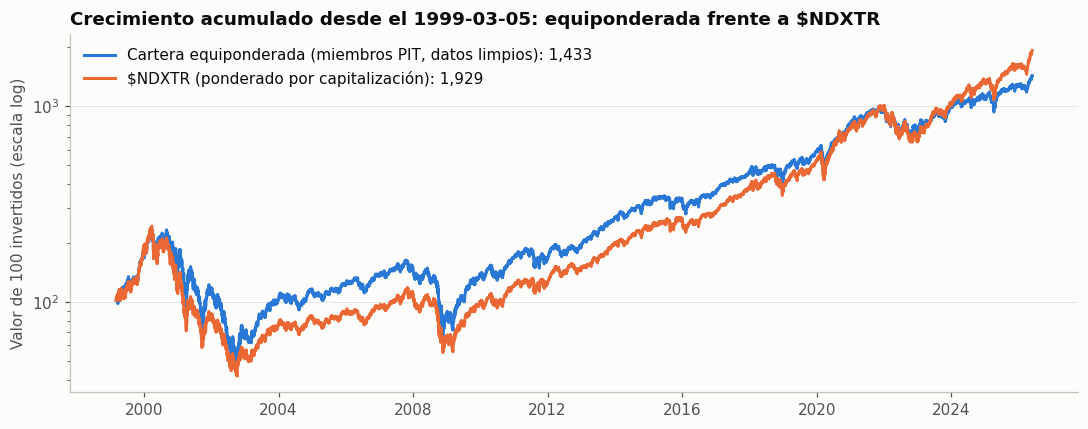

In [29]:
desde = ew['$NDXTR'].first_valid_index()
crec = (1 + ew.loc[desde:, ['despues', '$NDXTR']].fillna(0)).cumprod() * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(crec.index, crec['despues'], color=COLOR['azul'],
        label=f"Cartera equiponderada (miembros PIT, datos limpios): {crec['despues'].iloc[-1]:,.0f}")
ax.plot(crec.index, crec['$NDXTR'], color=COLOR['naranja'],
        label=f"$NDXTR (ponderado por capitalización): {crec['$NDXTR'].iloc[-1]:,.0f}")
ax.set_yscale('log')
ax.legend(loc='upper left')
ax.set_ylabel('Valor de 100 invertidos (escala log)')
ax.set_title(f'Crecimiento acumulado desde el {desde.date()}: equiponderada frente a $NDXTR')
plt.tight_layout()
plt.show()

**Lectura.**

- La correlación diaria con el `$NDX` es alta (≈ 0,96) y **prácticamente idéntica antes y después** de la limpieza: la limpieza no distorsiona la serie agregada.
- Los años con correlación más baja (2017, 2026) se explican por la ponderación. El índice está dominado por unas pocas megacapitalizaciones, mientras que la cartera equiponderada da el mismo peso a cada miembro. Es una diferencia de construcción, no un error de datos.
- Desde 2001 hasta 2020 la cartera equiponderada va por encima del `$NDXTR`. Entre 2020 y 2022 ambas van prácticamente a la par, y a partir de 2023 la concentración del índice en las grandes tecnológicas pone al `$NDXTR` por delante.

### 5.8 Prueba de ausencia de look-ahead (truncamiento)

Hasta aquí hemos **argumentado** que la limpieza solo usa información pasada. Esta prueba lo **demuestra**:

1. Se trunca el dataset (panel e historia de precios) en una fecha de corte `T`, como si estuviéramos ese día y no conociéramos nada posterior.
2. Se ejecuta la limpieza completa sobre los datos truncados.
3. Se comprueba que **todas las filas hasta `T` son idénticas** a las de la limpieza sobre el dataset completo.

Si alguna regla usara información futura (por ejemplo, la duración total de un hueco o un precio posterior), las filas cercanas a `T` cambiarían y la prueba fallaría.

Los cortes se eligen **en mitad de huecos**, donde un error de look-ahead se notaría más: durante la suspensión de WorldCom (2002) y al inicio de los huecos de WBD (2014) y TMUS (2018).

Primero se encapsula toda la limpieza en una sola función, `aplicar_limpieza`, y se comprueba que da exactamente el mismo resultado que los pasos de la sección 4. Quedan fuera:

- `valor_descartado` (opción A): usa la historia completa por construcción (ver 4.4);
- `evaluacion_fuente`: es documentación del dataset, no una regla;
- `salida_por_fin_cotizacion`: describe el final de un periodo, que es información del dataset.

In [30]:
def aplicar_limpieza(panel_base, historia, params):
    # Todas las reglas de limpieza causales, en el orden de las secciones 4 y 5
    F = params['FFILL_MAX_SESIONES']
    p = anadir_ultimo_precio_real(panel_base.copy(), historia)
    p = imputar_ffill_causal(p, F)
    p = clasificar_filas_sin_precio(p, resumen_huecos)
    p = recalcular_retornos(p, F)
    p = marcar_retornos_anomalos(p, params['UMBRAL_RET_ANOMALO'])
    p = detectar_saltos_split(p, params['UMBRAL_DIF_AJUSTE'], params['TOL_SPLIT'])
    p = marcar_precios_congelados(p, params['RACHA_CONGELADO'])
    return p


COLS_TEST = ['fecha_ultimo_precio_real', 'sesiones_desde_ultimo_precio', 'precio_imputado', 'close_totalreturn',
             'close_none', 'tipo_hueco', 'precio_utilizable', 'excluible', 'ret_tr_limpio', 'ret_none_limpio',
             'motivo_ret', 'ret_anomalo', 'accion_corporativa_ajustada', 'posible_split_no_ajustado',
             'capital_event_sesion_previa', 'sesiones_mismo_cierre', 'precio_congelado']

# 1) La función reproduce exactamente los pasos de la sección 4
completo = aplicar_limpieza(panel_base, historia, PARAMS)
pd.testing.assert_frame_equal(completo[COLS_TEST], panel[COLS_TEST])
print('✔ aplicar_limpieza reproduce exactamente el panel de la sección 4')

# 2) Truncamiento: las filas hasta T no pueden cambiar al quitar el futuro
resultados_test = []
for corte in PARAMS['CORTES_TEST_LOOKAHEAD']:
    T = pd.Timestamp(corte)
    truncado = aplicar_limpieza(panel_base[panel_base['date'] <= T], historia[historia['date'] <= T], PARAMS)
    referencia = completo.loc[completo['date'] <= T, COLS_TEST].reset_index(drop=True)
    pd.testing.assert_frame_equal(truncado[COLS_TEST].reset_index(drop=True), referencia)
    ultimo_dia = truncado['date'] == T
    resultados_test.append({'corte': corte, 'filas_comparadas': len(referencia),
                            'imputadas_hasta_T': int(truncado['precio_imputado'].sum()),
                            'imputadas_el_dia_T': int(truncado.loc[ultimo_dia, 'precio_imputado'].sum()),
                            'excluibles_el_dia_T': int(truncado.loc[ultimo_dia, 'excluible'].sum()),
                            'resultado': 'idénticas ✔'})
display(pd.DataFrame(resultados_test))
del completo, truncado

✔ aplicar_limpieza reproduce exactamente el panel de la sección 4


,corte,filas_comparadas,imputadas_hasta_T,imputadas_el_dia_T,excluibles_el_dia_T,resultado
0,2002-06-27,219225,25,1,4,idénticas ✔
1,2014-01-06,509324,34,1,4,idénticas ✔
2,2018-01-04,615643,42,1,0,idénticas ✔


**Control negativo: ¿la prueba detecta de verdad el look-ahead?** Una prueba que nunca falla no demuestra nada. Por eso aplicamos la misma comprobación a una limpieza **trampa**, que además rellena los huecos con el **siguiente** precio conocido (*backfill*, que mira al futuro). Con el corte de 2014, en mitad de los huecos largos que terminan en 2015, la prueba debe detectar diferencias.

In [31]:
def limpieza_con_lookahead(panel_base, historia, params):
    p = aplicar_limpieza(panel_base, historia, params)
    p['close_totalreturn'] = p.groupby('assetid')['close_totalreturn'].bfill()   # ¡regla tramposa!
    return p


T = pd.Timestamp('2014-01-06')
trampa_completo = limpieza_con_lookahead(panel_base, historia, PARAMS)
trampa_truncado = limpieza_con_lookahead(panel_base[panel_base['date'] <= T], historia[historia['date'] <= T], PARAMS)
a = trampa_truncado['close_totalreturn'].reset_index(drop=True)
b = trampa_completo.loc[trampa_completo['date'] <= T, 'close_totalreturn'].reset_index(drop=True)
distintas = ~((a == b) | (a.isna() & b.isna()))
print(f'Limpieza trampa (backfill): {int(distintas.sum()):,} filas hasta {T.date()} cambian al conocer el futuro')
assert distintas.any(), 'El control negativo debería fallar'
print('✔ la prueba de truncamiento detecta el look-ahead cuando existe')
del trampa_completo, trampa_truncado

Limpieza trampa (backfill): 11,408 filas hasta 2014-01-06 cambian al conocer el futuro
✔ la prueba de truncamiento detecta el look-ahead cuando existe


**Lectura.** En los tres cortes las filas son idénticas con y sin el futuro, incluidas las del propio día `T`, que caen en mitad de un hueco (columna `imputadas_el_dia_T`). La limpieza es **causal**: todo lo que marca o rellena en una fecha se habría podido calcular ese mismo día. En cambio, la limpieza trampa con *backfill* hace fallar la prueba, lo que confirma que esta es capaz de detectar el look-ahead.

## 6. Informe antes / después

### 6.1 Cobertura por año

In [32]:
anio = panel['date'].dt.year
g = panel.groupby(anio)
cobertura_anual = pd.DataFrame({
    'filas_miembro': g.size(),
    'valores_miembro': g['assetid'].nunique(),
    'pct_precio_real_antes': 100 * g['has_price'].mean(),
    'pct_precio_utilizable_despues': 100 * g['precio_utilizable'].mean(),
    'pct_ret_valido_antes': 100 * panel['return_totalreturn_1_session'].notna().groupby(anio).mean(),
    'pct_ret_valido_despues': 100 * panel['ret_tr_limpio'].notna().groupby(anio).mean(),
    'filas_imputadas': g['precio_imputado'].sum(),
    'filas_excluibles': g['excluible'].sum(),
    'valores_con_excluibles': panel[panel['excluible']].groupby(anio[panel['excluible']])['assetid'].nunique(),
    'ret_acumulado_tras_hueco': (panel['motivo_ret'] == 'acumulado_tras_hueco_corto').groupby(anio).sum(),
    'ret_nan_tras_hueco_largo': (panel['motivo_ret'] == 'tras_hueco_largo').groupby(anio).sum(),
    'ret_anomalos': g['ret_anomalo'].sum(),
}).fillna(0)
cobertura_anual.index.name = 'anio'
display(cobertura_anual.round(2))

,filas_miembro,valores_miembro,pct_precio_real_antes,pct_precio_utilizable_despues,pct_ret_valido_antes,pct_ret_valido_despues,filas_imputadas,filas_excluibles,valores_con_excluibles,ret_acumulado_tras_hueco,ret_nan_tras_hueco_largo,ret_anomalos
anio,,,,,,,,,,,,
1993,6208,123,98.1600,98.2100,98.1300,98.2100,3,111,2.0000,2,0,0
1994,24440,107,95.8700,95.9200,95.8700,95.9200,11,998,4.0000,1,0,2
1995,25200,122,96.0300,96.0400,96.0300,96.0400,1,999,4.0000,1,0,2
1996,25400,122,97.0000,97.0000,96.9900,97.0000,1,762,5.0000,1,0,0
1997,25300,108,96.4400,96.4400,96.4300,96.4400,1,900,4.0000,1,0,2
1998,25199,125,95.7000,95.7000,95.6900,95.7000,1,1083,5.0000,1,0,1
1999,25200,131,94.5800,94.5800,94.5800,94.5800,0,1365,7.0000,0,0,0
2000,25200,117,94.0400,94.0400,94.0400,94.0400,0,1503,6.0000,0,0,3
2001,24778,119,95.0200,95.0200,95.0200,95.0200,0,1235,5.0000,0,0,9


### 6.2 Resumen por decisión

Filas y valores afectados por cada decisión de limpieza o validación. Estas filas forman también el registro `log_decisiones.parquet` que se exporta en la sección 7.

In [33]:
DECISIONES = {
    '4.2 precio imputado (ffill causal)': panel['precio_imputado'],
    '4.3 excluible: prolongado sin imputar': panel['tipo_hueco'] == 'prolongado_sin_imputar',
    '4.3 excluible: sin precio previo': panel['tipo_hueco'] == 'sin_precio_previo',
    '4.4 valor descartado (opción A)': panel['valor_descartado'],
    '4.5 retorno acumulado tras hueco corto': panel['motivo_ret'] == 'acumulado_tras_hueco_corto',
    '4.5 retorno NaN tras hueco largo': panel['motivo_ret'] == 'tras_hueco_largo',
    '5.2 OHLC incoherente': panel['ohlc_incoherente'],
    '5.3 retorno anómalo': panel['ret_anomalo'],
    '5.3 posible split no ajustado': panel['posible_split_no_ajustado'],
    '5.3 operación corporativa ajustada (info)': panel['accion_corporativa_ajustada'],
    '5.4 precio congelado': panel['precio_congelado'],
    '5.6 salida por fin de cotización (info)': panel['salida_por_fin_cotizacion'],
}
resumen_decisiones = pd.DataFrame([
    {'decision': d, 'filas': int(m.sum()), 'pct_panel': 100 * m.mean(), 'valores': panel.loc[m, 'assetid'].nunique()}
    for d, m in DECISIONES.items()]).set_index('decision')
display(resumen_decisiones)

antes_despues = pd.DataFrame({
    'antes': [len(panel), int(panel['has_price'].sum()), int((~panel['has_price']).sum()),
              int(panel['return_totalreturn_1_session'].notna().sum()), panel['assetid'].nunique(),
              panel.loc[~panel['has_price'], 'assetid'].nunique()],
    'despues': [len(panel), int(panel['precio_utilizable'].sum()), int(panel['excluible'].sum()),
                int(panel['ret_tr_limpio'].notna().sum()), panel.loc[~panel['valor_descartado'], 'assetid'].nunique(),
                panel.loc[panel['excluible'], 'assetid'].nunique()],
}, index=['filas del panel', 'filas con precio utilizable', 'filas sin precio utilizable',
          'filas con retorno diario válido', 'valores en el universo', 'valores con alguna fila sin precio'])
antes_despues['cambio'] = antes_despues['despues'] - antes_despues['antes']
display(antes_despues)

,filas,pct_panel,valores
decision,,,
4.2 precio imputado (ffill causal),46,0.0055,16
4.3 excluible: prolongado sin imputar,10317,1.2419,8
4.3 excluible: sin precio previo,14612,1.7589,9
4.4 valor descartado (opción A),0,0.0000,0
4.5 retorno acumulado tras hueco corto,18,0.0022,12
4.5 retorno NaN tras hueco largo,5,0.0006,4
5.2 OHLC incoherente,0,0.0000,0
5.3 retorno anómalo,32,0.0039,25
5.3 posible split no ajustado,2,0.0002,2


,antes,despues,cambio
filas del panel,830759,830759,0
filas con precio utilizable,805784,805830,46
filas sin precio utilizable,24975,24929,-46
filas con retorno diario válido,805755,805819,64
valores en el universo,473,473,0
valores con alguna fila sin precio,28,16,-12


**Lectura.** La limpieza **no cambia el universo**: mismas filas y mismos valores, como exige el enfoque point-in-time. Lo que cambia es que cada fila queda etiquetada:

- unas pocas decenas de filas pasan a tener precio por la imputación causal de huecos cortos;
- el resto de huecos (≈ 3 % del panel, casi todos de los 16 valores con particiones dañadas) quedan marcados como `excluible`, con su motivo;
- los retornos tras un hueco largo dejan de ser un salto multianual atribuido a un día.

El dataset sigue **sin estar certificado** para un backtest sin matices (`ready_for_unqualified_backtest = false`). Cualquier resultado de los años 1994–2014 y 2018–2024 debe mencionar que una parte del índice (≈ 4 % de las filas) no tiene precio y cómo se ha tratado.

## 7. Exportación

Se lee el panel original **completo** (todas sus columnas, con pyarrow) una sola vez y se le aplican los cambios:

- en las filas imputadas, se rellenan `open/high/low/close/unadjusted_close` de las cuatro variantes con el último cierre real; el resto de columnas originales no se toca;
- se añaden las columnas nuevas de la limpieza.

**Archivos generados en `datos_limpios/`:**

| Archivo | Contenido |
|---|---|
| `panel_pit_limpio.parquet` | Panel point-in-time: 48 columnas originales + columnas de limpieza. |
| `log_decisiones.parquet` | Una fila por (fila del panel × decisión aplicada). |
| `cobertura_anual.parquet` | Tabla de la sección 6.1. |
| `informe_limpieza.json` | Parámetros, versiones, hashes de entrada y salida, y resumen de resultados. |

In [34]:
COLUMNAS_NUEVAS = {
    'precio_imputado': 'True si el precio se ha rellenado con el último cierre real (ffill causal, sección 4.2)',
    'sesiones_desde_ultimo_precio': 'Sesiones $NDX desde el último precio real estrictamente anterior',
    'fecha_ultimo_precio_real': 'Fecha del último precio real estrictamente anterior',
    'tipo_hueco': 'ninguno | imputado_ffill | prolongado_sin_imputar | sin_precio_previo',
    'evaluacion_fuente': 'Evaluación del dataset original para el valor (solo filas sin precio real)',
    'precio_utilizable': 'has_price | precio_imputado',
    'excluible': 'True si la fila no tiene precio utilizable (no se borra: sigue siendo miembro)',
    'valor_descartado': 'True si el valor se descarta entero (opción A; False con la opción B elegida)',
    'ret_tr_limpio': 'Retorno diario sobre close_totalreturn (sección 4.5); NaN si no es fiable',
    'ret_none_limpio': 'Ídem sobre close_none (solo para validar splits)',
    'motivo_ret': 'normal | imputado_cero | acumulado_tras_hueco_corto | tras_hueco_largo | sin_precio | primer_precio',
    'ret_anomalo': f"|ret_tr_limpio| > {PARAMS['UMBRAL_RET_ANOMALO']}",
    'accion_corporativa_ajustada': 'El precio sin ajustar salta y el ajustado no (split u operación corporativa bien ajustada)',
    'posible_split_no_ajustado': 'Retorno anómalo con factor ~entero en ambas series: revisar',
    'capital_event_sesion_previa': 'capital_event de la fila de pertenencia anterior del valor (Norgate lo marca la víspera)',
    'sesiones_mismo_cierre': 'Sesiones seguidas, hasta ese día, con el mismo close_none (solo filas con precio real)',
    'precio_congelado': f"sesiones_mismo_cierre >= {PARAMS['RACHA_CONGELADO']} (racha contada solo hacia atrás)",
    'salida_por_fin_cotizacion': 'Última sesión de un periodo que termina porque termina la serie de precios',
    'ohlc_incoherente': 'low/high incoherentes con open/close en filas con precio real',
}

t0 = time.time()
tabla = pq.read_table(DIR_ORIGEN / 'panel_pit_diario.parquet')
esquema_original = tabla.schema
tabla = tabla.sort_by([('date', 'ascending'), ('assetid', 'ascending')])
# Alineación fila a fila con el panel de trabajo
assert (tabla['assetid'].to_numpy() == panel['assetid'].to_numpy()).all()
assert (pd.to_datetime(tabla['date'].to_pandas()).to_numpy() == panel['date'].to_numpy()).all()

# 1) Precios imputados: se sustituyen solo las posiciones imputadas (el resto, incluidos nulos, intacto)
mascara = np.zeros(tabla.num_rows, dtype=bool)
mascara[imputados['fila'].to_numpy()] = True
cols_precio = [f'{c}_{v}' for v in VARIANTES for c in ['open', 'high', 'low', 'close', 'unadjusted_close']]
for col in cols_precio:
    i = tabla.schema.get_field_index(col)
    original = tabla[col].combine_chunks()
    nueva = pc.replace_with_mask(original, pa.array(mascara), pa.array(imputados[col].to_numpy(), type=original.type))
    tabla = tabla.set_column(i, col, nueva)

# 2) Columnas nuevas
nuevas = panel[list(COLUMNAS_NUEVAS)].copy()
nuevas['sesiones_desde_ultimo_precio'] = nuevas['sesiones_desde_ultimo_precio'].astype('Int32')
nuevas['fecha_ultimo_precio_real'] = nuevas['fecha_ultimo_precio_real'].dt.date
for col in COLUMNAS_NUEVAS:
    tabla = tabla.append_column(col, pa.Array.from_pandas(nuevas[col]))

# Metadatos: descripción de las columnas nuevas dentro del propio parquet
tabla = tabla.replace_schema_metadata({**(tabla.schema.metadata or {}),
                                       b'limpieza_columnas_nuevas': json.dumps(COLUMNAS_NUEVAS, ensure_ascii=False).encode(),
                                       b'limpieza_parametros': json.dumps(PARAMS).encode()})
ruta_panel = DIR_SALIDA / 'panel_pit_limpio.parquet'
pq.write_table(tabla, ruta_panel, compression='zstd')
print(f'Escrito {ruta_panel.name}: {tabla.num_rows:,} filas × {tabla.num_columns} columnas | {time.time() - t0:.1f} s')
del tabla

Escrito panel_pit_limpio.parquet: 830,759 filas × 67 columnas | 2.8 s


In [35]:
# Log de decisiones: una fila por (fila del panel, decisión)
log = pd.concat([
    panel.loc[m, ['date', 'assetid', 'membership_period', 'tipo_hueco', 'motivo_ret', 'ret_tr_limpio']]
    .assign(decision=d) for d, m in DECISIONES.items() if m.any()], ignore_index=True)
log.insert(2, 'simbolo', log['assetid'].map(SIMBOLO))
log.to_parquet(DIR_SALIDA / 'log_decisiones.parquet', index=False, compression='zstd')
cobertura_anual.reset_index().to_parquet(DIR_SALIDA / 'cobertura_anual.parquet', index=False)
print(f'log_decisiones: {len(log):,} filas')
display(log['decision'].value_counts().to_frame('filas'))

log_decisiones: 25,617 filas


,filas
decision,
4.3 excluible: sin precio previo,14612
4.3 excluible: prolongado sin imputar,10317
5.3 operación corporativa ajustada (info),358
5.4 precio congelado,179
5.6 salida por fin de cotización (info),48
4.2 precio imputado (ffill causal),46
5.3 retorno anómalo,32
4.5 retorno acumulado tras hueco corto,18
4.5 retorno NaN tras hueco largo,5


### 7.1 Verificación de la salida y de que el original no ha cambiado

Releemos la salida (metadatos y algunas columnas) para comprobar filas, claves únicas, que las 48 columnas originales siguen ahí con su tipo, y que las filas imputadas tienen precio. Al final se vuelven a calcular los SHA256 del dataset original para garantizar que no se ha modificado nada.

In [36]:
esquema_salida = pq.read_schema(ruta_panel)
assert pq.ParquetFile(ruta_panel).metadata.num_rows == len(panel)
for campo in esquema_original:
    assert esquema_salida.field(campo.name).type == campo.type, campo.name
salida = pd.read_parquet(ruta_panel, columns=['date', 'assetid', 'has_price', 'precio_imputado', 'close_totalreturn',
                                              'open_none', 'volume_none', 'excluible'])
assert not salida.duplicated(['date', 'assetid']).any()
assert salida.loc[salida['precio_imputado'], ['close_totalreturn', 'open_none']].notna().all().all()
assert salida.loc[salida['precio_imputado'], 'volume_none'].isna().all()
assert salida.loc[salida['excluible'], 'close_totalreturn'].isna().all()
assert (salida['has_price'] | salida['precio_imputado'] == ~salida['excluible']).all()
print('✔ salida verificada')
del salida

integridad_final, no_listados_final = verificar_integridad(DIR_ORIGEN)
assert integridad_final['ok'].all() and not no_listados_final
print('✔ dataset original intacto (SHA256 sin cambios)')

✔ salida verificada


✔ dataset original intacto (SHA256 sin cambios)


In [37]:
informe = {
    'notebook': 'notebooks/01_limpieza_datos.ipynb',
    'ejecutado_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'entorno': {'python': platform.python_version(), 'pandas': pd.__version__, 'pyarrow': pa.__version__,
                'numpy': np.__version__},
    'parametros': PARAMS,
    'decisiones': {
        'precio_para_retornos': 'close_totalreturn (close_none solo para validar splits)',
        'huecos_cortos': f"ffill causal hasta {PARAMS['FFILL_MAX_SESIONES']} sesiones, marcado en precio_imputado",
        'huecos_largos': 'se mantienen las filas sin precio, marcadas como excluible (no se inventan precios)',
        'valores_con_muchos_huecos': 'opción B: no se descarta ningún valor completo (evitar sesgo de supervivencia)',
        'retorno_tras_hueco_largo': 'NaN (motivo_ret = tras_hueco_largo)',
        'anomalias': 'se marcan (ret_anomalo, posible_split_no_ajustado, ohlc_incoherente, precio_congelado); no se borran',
        'salidas_por_fin_cotizacion': 'sin retorno de salida sintético; marcadas en salida_por_fin_cotizacion',
        'test_lookahead': f"filas idénticas con datos truncados en {PARAMS['CORTES_TEST_LOOKAHEAD']}",
    },
    'entrada': {'carpeta': NOMBRE_DATASET,
                'sha256': {k: v for k, v in HASHES_ENTRADA.items() if k.endswith('.parquet')}},
    'resultado': {
        'antes_despues': antes_despues.astype(int).to_dict(orient='index'),
        'decisiones': resumen_decisiones[['filas', 'valores']].astype(int).to_dict(orient='index'),
        'correlacion_ew_vs_ndx': {k: round(float(v), 4) for k, v in corr_total.items()},
    },
    'columnas_nuevas': COLUMNAS_NUEVAS,
    'salida': {p.name: sha256_archivo(p) for p in sorted(DIR_SALIDA.glob('*.parquet'))},
    'duracion_segundos': round(time.time() - T_INICIO, 1),
}
(DIR_SALIDA / 'informe_limpieza.json').write_text(json.dumps(informe, indent=2, ensure_ascii=False, default=str))
for p in sorted(DIR_SALIDA.iterdir()):
    print(f'{p.name:32s} {p.stat().st_size / 1e6:8.2f} MB')
print(f"\nDuración total: {informe['duracion_segundos']} s")

cobertura_anual.parquet              0.01 MB
informe_limpieza.json                0.01 MB
log_decisiones.parquet               0.10 MB
panel_pit_limpio.parquet            99.88 MB

Duración total: 13.3 s


## Resumen para los siguientes notebooks

- Leer **`datos_limpios/panel_pit_limpio.parquet`**: contiene una fila por valor y día de pertenencia, incluidas las deslistadas.
- Para retornos, usar **`ret_tr_limpio`**. Los `NaN` tienen su causa en `motivo_ret`.
- Los días con `excluible = True` el valor **era miembro pero no tiene precio**. Cada análisis debe declarar qué hace con ellos (lo más sencillo es excluirlos ese día y repartir el peso entre el resto de miembros).
- Revisar antes de usar: `ret_anomalo`, `posible_split_no_ajustado`, `ohlc_incoherente` y `precio_congelado`.
- `salida_por_fin_cotizacion` marca el último día de los valores que dejan de cotizar siendo miembros. Para un análisis de sensibilidad de quiebras, ver la sección 5.6.
- La limpieza está verificada como **causal** mediante la prueba de truncamiento (sección 5.8).
- Nunca filtrar por `is_delisted_snapshot`.